# Практическое занятие №1. Ансамблиевые методы машинного обучения

## Случайный лес (Random Forest) в задаче распознавания сорта вина

**Студент:** Галимский Дмитрий, группа 413м

---

## Постановка задачи

Винодельня сдаёт партию готового вина. Сорт задаёт всё: цену, срок выдержки,
тираж на этикетке. Разбирать партию вручную по органолептике долго и дорого,
а лабораторный анализ даёт для каждого образца **13 числовых характеристик**:
долю спирта, яблочную кислоту, зольность, щёлочность золы, магний, фенолы,
флавоноиды, красящие вещества, оттенок и так далее.

Значит, задача формулируется так: **по 13 химическим измерениям определить,
из какой лозы сделан образец**. Это задача **многоклассовой классификации**:
ответ дискретный, один из трёх сортов (`class_0`, `class_1`, `class_2`), а не
число, которое нужно приблизить.

Почему именно случайный лес:

* все 13 признаков **числовые, но измерены в несопоставимых единицах**:
  магний - сотни, зольность - единицы, нефлавоноидные фенолы - десятые доли.
  Случайный лес этому не мешает: каждое дерево ищет пороги вида «признак не
  больше значения», и от единиц измерения результат не зависит;
* граница между первым и третьим сортом **не плоская, а кусочно заданная**:
  в одном признаке между ними есть настоящий зазор, а в остальных диапазоны
  накладываются. Такие «ломаные» границы - родная стихия дерева решений;
* сорта **не равны по размеру** (59, 71 и 48 образцов), а ошибиться на редком
  сорте дороже, чем на частом. Лес даёт не одну общую цифру, а полный отчёт
  по каждому сорту, и это как раз то, что здесь нужно;
* лес из сотен деревьев **усредняет** их голоса и слабо зависит от того, какое
  дерево попалось первым. На маленькой выборке устойчивость стоит дороже, чем
  ещё пол-процента точности.

**Честное предупреждение сразу.** Датасет маленький: 178 строк и 13 признаков
на три класса. На таких данных случайный лес почти всегда показывает accuracy
около 0,95-1,0. Это число **не доказывает**, что лес хорош: оно может
измерять не способность модели, а удачный выбор порогов. В работе это
проверено прямо в числах: в разделах 6.5 и 6.6 сравнивается лес с одиночным
деревом и оценивается, сколько признаков реально нужно, а в разделе 7.2
разбираются все конкретные ошибки.

Работа построена по шагам: данные -> проверка и очистка -> разведочный анализ ->
подготовка -> модель -> обучение -> оценка -> выводы. Выбор модели делается по
валидации, тестовая выборка открывается один раз в разделе «Оценка».


In [1]:
# Зависимости.
# В Colab этот стек уже установлен, локально pip доставит недостающее.
%pip install -q numpy pandas scikit-learn matplotlib seaborn

# Проверка версий: иначе ошибка всплывёт позже, в середине обучения.
import importlib

for _package in ("numpy", "pandas", "sklearn", "matplotlib", "seaborn"):
    _module = importlib.import_module(_package)
    print(f"{_package:12s} {_module.__version__}")


Note: you may need to restart the kernel to use updated packages.
numpy        2.5.3


pandas       3.0.5


sklearn      1.9.1


matplotlib   3.11.2


seaborn      0.13.2


In [2]:
# Все импорты

# Датасет из пакета sklearn, интернет не нужен
from sklearn.datasets import load_wine

# Таблица, срезы, сводная статистика, группировка
import pandas as pd

# Численные операции: массивы, средние, стандартная ошибка доли
import numpy as np

# Графики: pyplot - полотна и оси, seaborn - heatmap, boxplot, barplot
import matplotlib.pyplot as plt
import seaborn as sns

# Одиночное дерево берём не для красоты: сравнение «один ствол против
# всей рощи» - самая честная проверка того, что даёт бэггинг.
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

# Базовая линия: модель, которая игнорирует признаки и всегда называет
# самый частый сорт. Ниже неё результат не имеет смысла.
from sklearn.dummy import DummyClassifier

# Разбиение выборки, стратифицированные фолды, кросс-валидация
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

# Опорная точка: сосед по всем признакам. Его ошибки показывают,
# насколько сложна сама задача, а не насколько хороша наша модель.
from sklearn.neighbors import NearestNeighbors

# Метрики качества многоклассовой классификации
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
)


In [3]:
# Воспроизводимость: фиксируем генератор случайных чисел, иначе каждый
# запуск ноутбука давал бы немного другие метрики.
SEED = 42
np.random.seed(SEED)

# Графики попадают в вывод ноутбука как картинки - это inline-режим.
%matplotlib inline

# Число деревьев: выигрыш заканчивается к 25-50 деревьям, 300 берём
# с запасом - на 106 обучающих строках это меньше секунды.
N_ESTIMATORS = 300
N_JOBS = -1

# Усреднение МАКРО, а не взвешенное по размеру класса: каждый сорт
# получает одинаковый вес, и ошибка на редком class_2 не потеряется
# среди 15 верно распознанных class_1. При перекосе взвешенное
# усреднение начало бы замалчивать именно то, что дорого.
AVERAGE = "macro"

# Названия сортов задаём один раз: в цветах, отчётах и подписях к
# осям. Коды 0/1/2 заменяем словами, иначе в отчётах стояли бы цифры.
CLASS_NAMES = ["class_0", "class_1", "class_2"]
CLASS_RU = {
    "class_0": "сорт 0",
    "class_1": "сорт 1",
    "class_2": "сорт 2",
}
CLASS_COLORS = {"class_0": "#55A868", "class_1": "#DD8452", "class_2": "#4C72B0"}

# Русские названия признаков: в модели остаются английские имена из
# набора, на графиках подписи читаются без словаря.
FEATURE_RU = {
    "alcohol": "доля спирта, %",
    "malic_acid": "яблочная кислота",
    "ash": "зольность",
    "alcalinity_of_ash": "щелочность золы",
    "magnesium": "магний",
    "total_phenols": "все фенолы",
    "flavanoids": "флавоноиды",
    "nonflavanoid_phenols": "нефлавоноидные фенолы",
    "proanthocyanins": "проантоцианы",
    "color_intensity": "интенсивность цвета",
    "hue": "оттенок",
    "od280/od315_of_diluted_wines": "поглощение OD280/OD315",
    "proline": "пролин",
}

# Единый стиль оформления всех графиков ноутбука
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

print(f"зерно генератора: {SEED}")
print(f"деревьев в лесу: {N_ESTIMATORS}, потоков CPU: {N_JOBS}")
print(f"усреднение метрик по классам: {AVERAGE}")


зерно генератора: 42
деревьев в лесу: 300, потоков CPU: -1
усреднение метрик по классам: macro


## 1. Данные

### 1.1 Какой датасет и почему он

**Wine** входит в `sklearn.datasets`, то есть физически лежит в пакете
`scikit-learn`. Загрузка идёт одной командой, без сети и без ручного файла,
поэтому ноутбук запускается одинаково и на машине, и в облаке.

Набор собран в 1970-х годах в итальянской области Пьемонт: химический анализ
178 образцов из одного региона, сделанных из лоз трёх сортов. Автора в самом
наборе не сохранилось, но для модели это неважно, а для выводов - очень
важно: все образцы сделаны **в одном хозяйстве, в одном сезоне, по одной
методике**.

Схема данных: **178 строк, 13 числовых признаков, 3 класса**.

| Признак | Единица | Что измеряется |
|---|---|---|
| `alcohol` | объёмные проценты | доля спирта |
| `malic_acid` | г/л | яблочная кислота |
| `ash` | г/л | зольность, то есть нелетучий остаток после выпаривания |
| `alcalinity_of_ash` | мг CaCO3 / 100 мл | щёлочность золы |
| `magnesium` | мг/л | магний |
| `total_phenols` | мг/л | все фенольные соединения |
| `flavanoids` | мг/л | подмножество фенолов - флавоноиды |
| `nonflavanoid_phenols` | мг/л | остальные фенолы |
| `proanthocyanins` | мг/л | проантоцианы, отвечают за терпкость |
| `color_intensity` | условные единицы | насыщенность цвета |
| `hue` | условные единицы | оттенок |
| `od280/od315_of_diluted_wines` | отношение поглощения | показатель окисления и старения |
| `proline` | мг/л | аминокислота пролин |
| `class` (**цель**) | - | **сорт вина**: `class_0`, `class_1`, `class_2` |

### 1.2 О чём стоит подумать сразу

Три обстоятельства, которые определяют всю работу:

1. **Классы не равны.** 59, 71 и 48 образцов: отношение 1,48 к 1. Это не
   перекос, который ломает метрики, но и не идеальный баланс, на котором
   accuracy ничего не значит.
2. **Признаки измерены в разных единицах и с разным разбросом**: магний лежит
   в сотнях, а нефлавоноидные фенолы - в десятых долях. Модель, которая умеет
   только сравнивать с порогами, от этого не страдает; модель, которая
   усредняет веса, - страдала бы. Это отдельный аргумент в пользу дерева.
3. **Задача не выглядит тривиальной.** Проверка в разделе 3.4 покажет: даже
   простейшая модель «ближайший сосед по всем 13 признакам» ошибается
   примерно в четверти случаев. Значит, высокая точность леса будет
   результатом работы модели, а не свойством данных.


In [4]:
# Загрузка: load_wine отдаёт готовый набор из sklearn. Данные лежат в
# атрибутах: data - матрица признаков, target - номера классов,
# feature_names и target_names - их названия.
wine = load_wine()

FEATURE_COLUMNS = list(wine.feature_names)
TARGET = "class"

# Собираем таблицу: признаки и целевая переменная в одном DataFrame.
# Коды классов заменяем словами, иначе в отчётах стоял бы голый номер.
CODE_TO_NAME = {index: name for index, name in enumerate(wine.target_names)}
raw = pd.DataFrame(wine.data, columns=FEATURE_COLUMNS)
raw[TARGET] = [CODE_TO_NAME[index] for index in wine.target]

print(f"объект: {type(wine).__name__}, строк: {len(raw)}, признаков: {len(FEATURE_COLUMNS)}")
print(f"имена сортов: {CLASS_NAMES}")
print("источник: пакет sklearn.datasets, сеть не требуется")
raw.head()


объект: Bunch, строк: 178, признаков: 13
имена сортов: ['class_0', 'class_1', 'class_2']
источник: пакет sklearn.datasets, сеть не требуется


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,class
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,class_0


In [5]:
# Что означает каждый столбец, в каких единицах измерен и как распределён.
# Без такой таблицы графики нельзя читать осмысленно: условие
# "proline <= 985" ничего не говорит, пока не известно, что пролин
# измеряется в миллиграммах на литр. Границы берём из самих данных.
MEANING = pd.DataFrame({
    "признак": FEATURE_COLUMNS + [TARGET],
    "по-русски": [FEATURE_RU[name] for name in FEATURE_COLUMNS] + ["сорт вина"],
    "единица": [
        "% об.", "г/л", "г/л", "мг CaCO3/100 мл", "мг/л",
        "мг/л", "мг/л", "мг/л", "мг/л", "усл. ед.", "усл. ед.",
        "отношение", "мг/л", "-",
    ],
    "минимум": [f"{value:.2f}" for value in raw[FEATURE_COLUMNS].min()] + ["-"],
    "максимум": [f"{value:.2f}" for value in raw[FEATURE_COLUMNS].max()] + ["-"],
    "свойств": list(raw[FEATURE_COLUMNS].nunique()) + [raw[TARGET].nunique()],
}).set_index("признак")

MEANING


,по-русски,единица,минимум,максимум,свойств
признак,,,,,
alcohol,"доля спирта, %",% об.,11.03,14.83,126
malic_acid,яблочная кислота,г/л,0.74,5.80,133
ash,зольность,г/л,1.36,3.23,79
alcalinity_of_ash,щелочность золы,мг CaCO3/100 мл,10.60,30.00,63
magnesium,магний,мг/л,70.00,162.00,53
total_phenols,все фенолы,мг/л,0.98,3.88,97
flavanoids,флавоноиды,мг/л,0.34,5.08,132
nonflavanoid_phenols,нефлавоноидные фенолы,мг/л,0.13,0.66,39
proanthocyanins,проантоцианы,мг/л,0.41,3.58,101


In [6]:
# Типы столбцов и сводная статистика. Если вместо числа оказалась буква
# или пустое поле, pandas проставит object - первый признак "битых" данных.
print(raw.dtypes)
print()
print(raw[FEATURE_COLUMNS].describe().round(3).T)


alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
class                               str
dtype: object

                              count     mean      std     min      25%      50%      75%      max
alcohol                       178.0   13.001    0.812   11.03   12.362   13.050   13.678    14.83
malic_acid                    178.0    2.336    1.117    0.74    1.602    1.865    3.082     5.80
ash                           178.0    2.367    0.274    1.36    2.210    2.360    2.558     3.23
alcalinity_of_ash             178

,образцов,"доля, %"
сорт,,
class_0,59,33.15
class_1,71,39.89
class_2,48,26.97


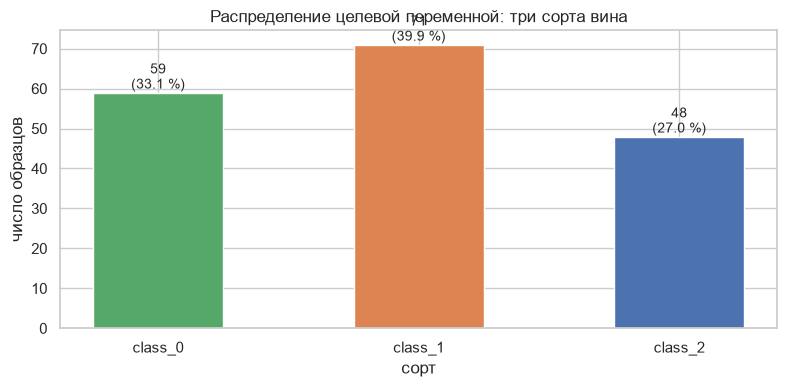

образцов в наборе: 178
образцов по сортам: {'class_0': 59, 'class_1': 71, 'class_2': 48}
соотношение размеров сортов: 1.48 к 1
потолок для базовой линии: 39.89%

то есть модель, которая не смотрит ни на один признак и всегда
называет самый частый сорт, набирает ровно столько процентов.


In [7]:
# Целевая переменная отдельно: её распределение определяет, какие
# метрики имеют смысл. Классы почти равны, но макро-усреднение
# всё равно обязательно.
class_table = pd.DataFrame({
    "образцов": raw[TARGET].value_counts().reindex(CLASS_NAMES),
    "доля, %": (raw[TARGET].value_counts(normalize=True).reindex(CLASS_NAMES) * 100).round(2),
})
class_table.index.name = "сорт"
display(class_table)

figure, axis = plt.subplots(figsize=(8, 4))
bars = axis.bar(class_table.index, class_table["образцов"],
                color=[CLASS_COLORS[name] for name in class_table.index], width=0.5)
axis.set_title("Распределение целевой переменной: три сорта вина")
axis.set_xlabel("сорт")
axis.set_ylabel("число образцов")
for bar, number, share in zip(bars, class_table["образцов"], class_table["доля, %"]):
    axis.text(bar.get_x() + bar.get_width() / 2, number + 1,
              f"{number}\n({share:.1f} %)", ha="center", fontsize=10)
figure.tight_layout()
plt.show()

class_ratio = class_table["образцов"].max() / class_table["образцов"].min()
print(f"образцов в наборе: {len(raw)}")
print("образцов по сортам:", class_table["образцов"].to_dict())
print(f"соотношение размеров сортов: {class_ratio:.2f} к 1")
print(f"потолок для базовой линии: {class_table['доля, %'].max():.2f} %")
print("\nто есть модель, которая не смотрит ни на один признак и всегда")
print("называет самый частый сорт, набирает ровно столько процентов.")


## 2. Проверка и очистка

Очистку нужно проводить **вслепую**: даже если данные выглядят чистыми, сам код
проверок обязателен - иначе неизвестно, чистые они или просто ещё не проверены.
По требованию к оформлению код должен быть в работе в любом случае.

Ниже пять проверок: пропуски, дубликаты, противоречия разметки, значения вне
физически возможного диапазона и выбросы.


In [8]:
# Пропуски: без них модель либо падает, либо молча обучается
# на "пустых" строках.
missing_frame = pd.DataFrame({
    "пропусков": raw.isna().sum(),
    "доля, %": (100 * raw.isna().sum() / len(raw)).round(4),
})
missing_frame.index.name = "столбец"

print("всего пропусков в таблице:", int(raw.isna().sum().sum()))
print("строк хотя бы с одним пропуском:", int(raw.isna().any(axis=1).sum()))
display(missing_frame)


всего пропусков в таблице: 0
строк хотя бы с одним пропуском: 0


,пропусков,"доля, %"
столбец,,
alcohol,0,0.0
malic_acid,0,0.0
ash,0,0.0
alcalinity_of_ash,0,0.0
magnesium,0,0.0
total_phenols,0,0.0
flavanoids,0,0.0
nonflavanoid_phenols,0,0.0
proanthocyanins,0,0.0


In [9]:
# Стратегия на случай пропусков: числовые признаки заполняем медианой -
# она устойчива к выбросам и не сдвигает распределение. Сейчас код
# ничего не меняет, потому что пропусков нет, но решение зафиксировано.
medians = raw[FEATURE_COLUMNS].median()
clean = raw.copy()
clean[FEATURE_COLUMNS] = clean[FEATURE_COLUMNS].fillna(medians)

print("пропусков до заполнения:", int(raw.isna().sum().sum()),
      "- после:", int(clean.isna().sum().sum()))
print("строк после заполнения:", len(clean))
print("медианы числовых признаков:")
print(medians.round(2).to_string())


пропусков до заполнения: 0 - после: 0
строк после заполнения: 178
медианы числовых признаков:
alcohol                          13.05
malic_acid                        1.87
ash                               2.36
alcalinity_of_ash                19.50
magnesium                        98.00
total_phenols                     2.36
flavanoids                        2.13
nonflavanoid_phenols              0.34
proanthocyanins                   1.56
color_intensity                   4.69
hue                               0.96
od280/od315_of_diluted_wines      2.78
proline                         673.50


In [10]:
# Дубликаты. Различаем три ситуации: полный повтор строки, повтор
# только по признакам (те же измерения у разных сортов), противоречие -
# одни признаки с разными метками, то есть ошибка разметки.
full_duplicates = int(clean.duplicated().sum())
feature_duplicates = int(clean.duplicated(subset=FEATURE_COLUMNS).sum())
labels_per_vector = clean.groupby(FEATURE_COLUMNS, observed=True)[TARGET].nunique()
contradictions = int((labels_per_vector > 1).sum())

print("полных дубликатов (лишних копий строки):", full_duplicates)
print("повторов по набору признаков (без цели):", feature_duplicates)
print("противоречий (одни признаки - разные сорта):", contradictions)

if full_duplicates or feature_duplicates:
    # Удаляем ровно лишние копии: drop_duplicates оставляет первую встречу.
    clean = clean.drop_duplicates(subset=FEATURE_COLUMNS, keep="first").reset_index(drop=True)
    print("после удаления дубликатов осталось строк:", len(clean))
else:
    print("удалять нечего: каждое измерение в наборе встречается один раз")


полных дубликатов (лишних копий строки): 0
повторов по набору признаков (без цели): 0
противоречий (одни признаки - разные сорта): 0
удалять нечего: каждое измерение в наборе встречается один раз


In [11]:
# Аномалия первого типа - значение вне физически возможного диапазона:
# доля спирта не бывает 60%, магний не бывает 5000 мг/л - это ошибка
# записи или смешение единиц. Поэтому границы взяты заведомо
# невозможные, а не типичные: «нормальный» образец в химии вина - это
# вино, сваренное по технологии. Рядом печатается запас до границы,
# чтобы порог не оказался выдумкой.
IMPOSSIBLE = {
    "alcohol": (0.0, 30.0),
    "malic_acid": (0.0, 20.0),
    "ash": (0.5, 10.0),
    "alcalinity_of_ash": (0.0, 60.0),
    "magnesium": (0.0, 500.0),
    "total_phenols": (0.0, 20.0),
    "flavanoids": (0.0, 20.0),
    "nonflavanoid_phenols": (0.0, 5.0),
    "proanthocyanins": (0.0, 20.0),
    "color_intensity": (0.0, 50.0),
    "hue": (0.0, 5.0),
    "od280/od315_of_diluted_wines": (0.0, 10.0),
    "proline": (0.0, 5000.0),
}

check_frame = pd.DataFrame({
    "минимум": clean[FEATURE_COLUMNS].min(),
    "максимум": clean[FEATURE_COLUMNS].max(),
})
check_frame["нижняя граница"] = [IMPOSSIBLE[name][0] for name in FEATURE_COLUMNS]
check_frame["верхняя граница"] = [IMPOSSIBLE[name][1] for name in FEATURE_COLUMNS]
check_frame["вне диапазона"] = [
    int((~clean[name].between(*IMPOSSIBLE[name])).sum()) for name in FEATURE_COLUMNS
]
# Запас считаем в процентах ширины диапазона: видно, насколько граница
# далека от самых крайних значений набора.
check_frame["запас, %"] = (100 * np.minimum(
    (check_frame["минимум"] - check_frame["нижняя граница"])
    / (check_frame["верхняя граница"] - check_frame["нижняя граница"]),
    (check_frame["верхняя граница"] - check_frame["максимум"])
    / (check_frame["верхняя граница"] - check_frame["нижняя граница"]),
)).round(1)

out_of_range = int(check_frame["вне диапазона"].sum())
display(check_frame.round(2))

print("значений вне физического диапазона:", out_of_range)
print("минимальный запас до границы, % ширины диапазона:",
      round(float(check_frame["запас, %"].min()), 1))


,минимум,максимум,нижняя граница,верхняя граница,вне диапазона,"запас, %"
alcohol,11.03,14.83,0.0,30.0,0,36.8
malic_acid,0.74,5.80,0.0,20.0,0,3.7
ash,1.36,3.23,0.5,10.0,0,9.1
alcalinity_of_ash,10.60,30.00,0.0,60.0,0,17.7
magnesium,70.00,162.00,0.0,500.0,0,14.0
total_phenols,0.98,3.88,0.0,20.0,0,4.9
flavanoids,0.34,5.08,0.0,20.0,0,1.7
nonflavanoid_phenols,0.13,0.66,0.0,5.0,0,2.6
proanthocyanins,0.41,3.58,0.0,20.0,0,2.0
color_intensity,1.28,13.00,0.0,50.0,0,2.6


значений вне физического диапазона: 0
минимальный запас до границы, % ширины диапазона: 1.7


In [12]:
# Выбросы по правилу межквартильного размаха: выше Q3 + 1.5 * IQR или
# ниже Q1 - 1.5 * IQR. Метод не зависит от формы распределения и
# устойчив к "хвостам", в отличие от "среднего плюс две сигмы".
outlier_mask = pd.Series(False, index=clean.index)
fences = {}
for column in FEATURE_COLUMNS:
    first_quartile, third_quartile = clean[column].quantile([0.25, 0.75])
    interquartile = third_quartile - first_quartile
    low, high = first_quartile - 1.5 * interquartile, third_quartile + 1.5 * interquartile
    fences[column] = (low, high)
    outlier_mask |= (clean[column] < low) | (clean[column] > high)

outlier_count = int(outlier_mask.sum())
outlier_share = 100 * outlier_count / len(clean)

print("выбросов по правилу 1.5 * IQR:", outlier_count)
print(f"выбросов по правилу 1.5 * IQR: {outlier_count} ({outlier_share:.1f} % строк)")
print("\nсколько выбросов даёт каждый признак:")
print(pd.Series({name: int(((clean[name] < low) | (clean[name] > high)).sum())
                 for name, (low, high) in fences.items()}).to_string())


выбросов по правилу 1.5 * IQR: 17
выбросов по правилу 1.5 * IQR: 17 (9.6% строк)

сколько выбросов даёт каждый признак:
alcohol                         0
malic_acid                      3
ash                             3
alcalinity_of_ash               4
magnesium                       4
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 2
color_intensity                 4
hue                             1
od280/od315_of_diluted_wines    0
proline                         0


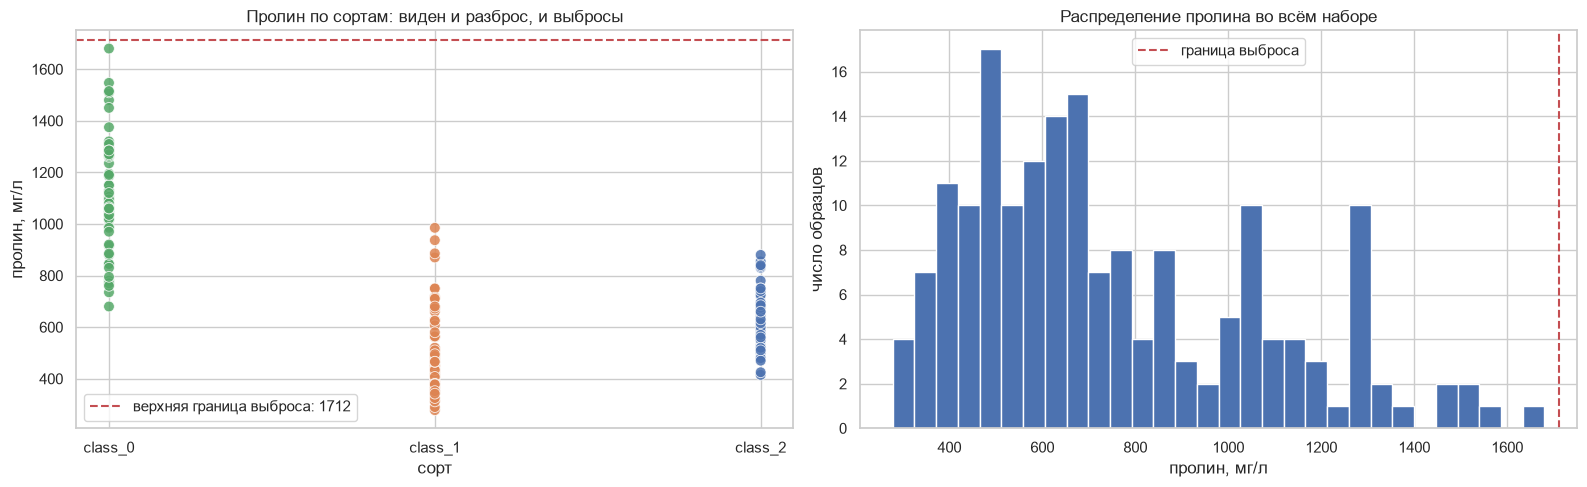

выбросов на каждый сорт:
class
class_0     1
class_1    10
class_2     6
больше всего выбросов у: class_1


In [13]:
# Выбросы на графике: ни одна точка за усами не выглядит опечаткой -
# все значения физически осмысленны. Высокий пролин - крепкое
# выдержанное вино, а не ошибка ввода.
figure, axes = plt.subplots(1, 2, figsize=(16, 5))
positions = clean[TARGET].map({name: index for index, name in enumerate(CLASS_NAMES)})

axes[0].scatter(positions, clean["proline"], c=[CLASS_COLORS[name] for name in clean[TARGET]],
                s=60, alpha=0.85, edgecolor="white", linewidth=0.6)
axes[0].axhline(fences["proline"][1], color="#C44E52", linestyle="--", linewidth=1.5,
                label=f"верхняя граница выброса: {fences['proline'][1]:.0f}")
axes[0].set_title("Пролин по сортам: виден и разброс, и выбросы")
axes[0].set_xlabel("сорт")
axes[0].set_ylabel("пролин, мг/л")
axes[0].set_xticks(range(3))
axes[0].set_xticklabels(CLASS_NAMES)
axes[0].legend()

axes[1].hist(clean["proline"], bins=30, color="#4C72B0", edgecolor="white")
axes[1].axvline(fences["proline"][1], color="#C44E52", linestyle="--", linewidth=1.5,
                label="граница выброса")
axes[1].set_title("Распределение пролина во всём наборе")
axes[1].set_xlabel("пролин, мг/л")
axes[1].set_ylabel("число образцов")
axes[1].legend()

figure.tight_layout()
plt.show()

# Выбросы по сортам: если бы они собирались в одном классе, это был бы
# сигнал о проблеме с меткой, а не о химическом разнообразии.
outliers_by_class = (clean.loc[outlier_mask, TARGET].value_counts()
                     .reindex(CLASS_NAMES).fillna(0).astype(int))
print("выбросов на каждый сорт:")
print(outliers_by_class.to_string())
print("больше всего выбросов у:", outliers_by_class.idxmax())


In [14]:
# Решение по выбросам: НЕ удаляем. «Нормальный» образец - не середина
# распределения, а вино по технологии: поздний сбор или долгая выдержка.
# Удаление выбросило бы из обучения партии, у которых выдержка сильнее
# всего меняет состав, то есть сузило бы диапазон сортов.
print("выбросов на каждый сорт:", outliers_by_class.to_dict())
print("всего строк:", len(clean), "- из них выбросов:", outlier_count)
print("\nрешение: оставляем все строки, удалять нечего.")
print("\nпочему это правильно именно здесь:")
print("1. выбросы есть у всех трёх сортов, значит это не сбой в одной партии;")
print("2. все {} значений лежат внутри заведомо невозможных границ из раздела 2.3;".format(
    outlier_count))
print("3. на химии это долгая выдержка и поздний сбор - реальные режимы виноделия.")


выбросов на каждый сорт: {'class_0': 1, 'class_1': 10, 'class_2': 6}
всего строк: 178 - из них выбросов: 17

решение: оставляем все строки, удалять нечего.

почему это правильно именно здесь:
1. выбросы есть у всех трёх сортов, значит это не сбой в одной партии;
2. все 17 значений лежат внутри заведомо невозможных границ из раздела 2.3;
3. на химии это долгая выдержка и поздний сбор - реальные режимы виноделия.


In [15]:
# Итог по очистке: все проверки нулевые, кроме выбросов, которые
# решено сохранить осознанно.
samples_per_feature = len(clean) / len(FEATURE_COLUMNS)

print("строк в исходном наборе:", len(raw))
print("строк после очистки:", len(clean))
print("признаков:", len(FEATURE_COLUMNS))
print("пропусков:", int(clean.isna().sum().sum()))
print("полных дубликатов:", full_duplicates)
print("противоречий разметки:", contradictions)
print("значений вне диапазона:", out_of_range)
print("выбросов оставлено:", outlier_count)
print(f"наблюдений на признак: {samples_per_feature:.1f}")
print("\nстрок не потеряно. Кодирование не требовалось - все признаки числовые.")


строк в исходном наборе: 178
строк после очистки: 178
признаков: 13
пропусков: 0
полных дубликатов: 0
противоречий разметки: 0
значений вне диапазона: 0
выбросов оставлено: 17
наблюдений на признак: 13.7

строк не потеряно. Кодирование не требовалось - все признаки числовые.


## 3. Разведочный анализ

Здесь решается главный вопрос работы: **чем сорта отличаются друг от друга**
и **где между ними проходит граница**. От ответа зависят и выбор модели, и
разбор ошибок в конце.


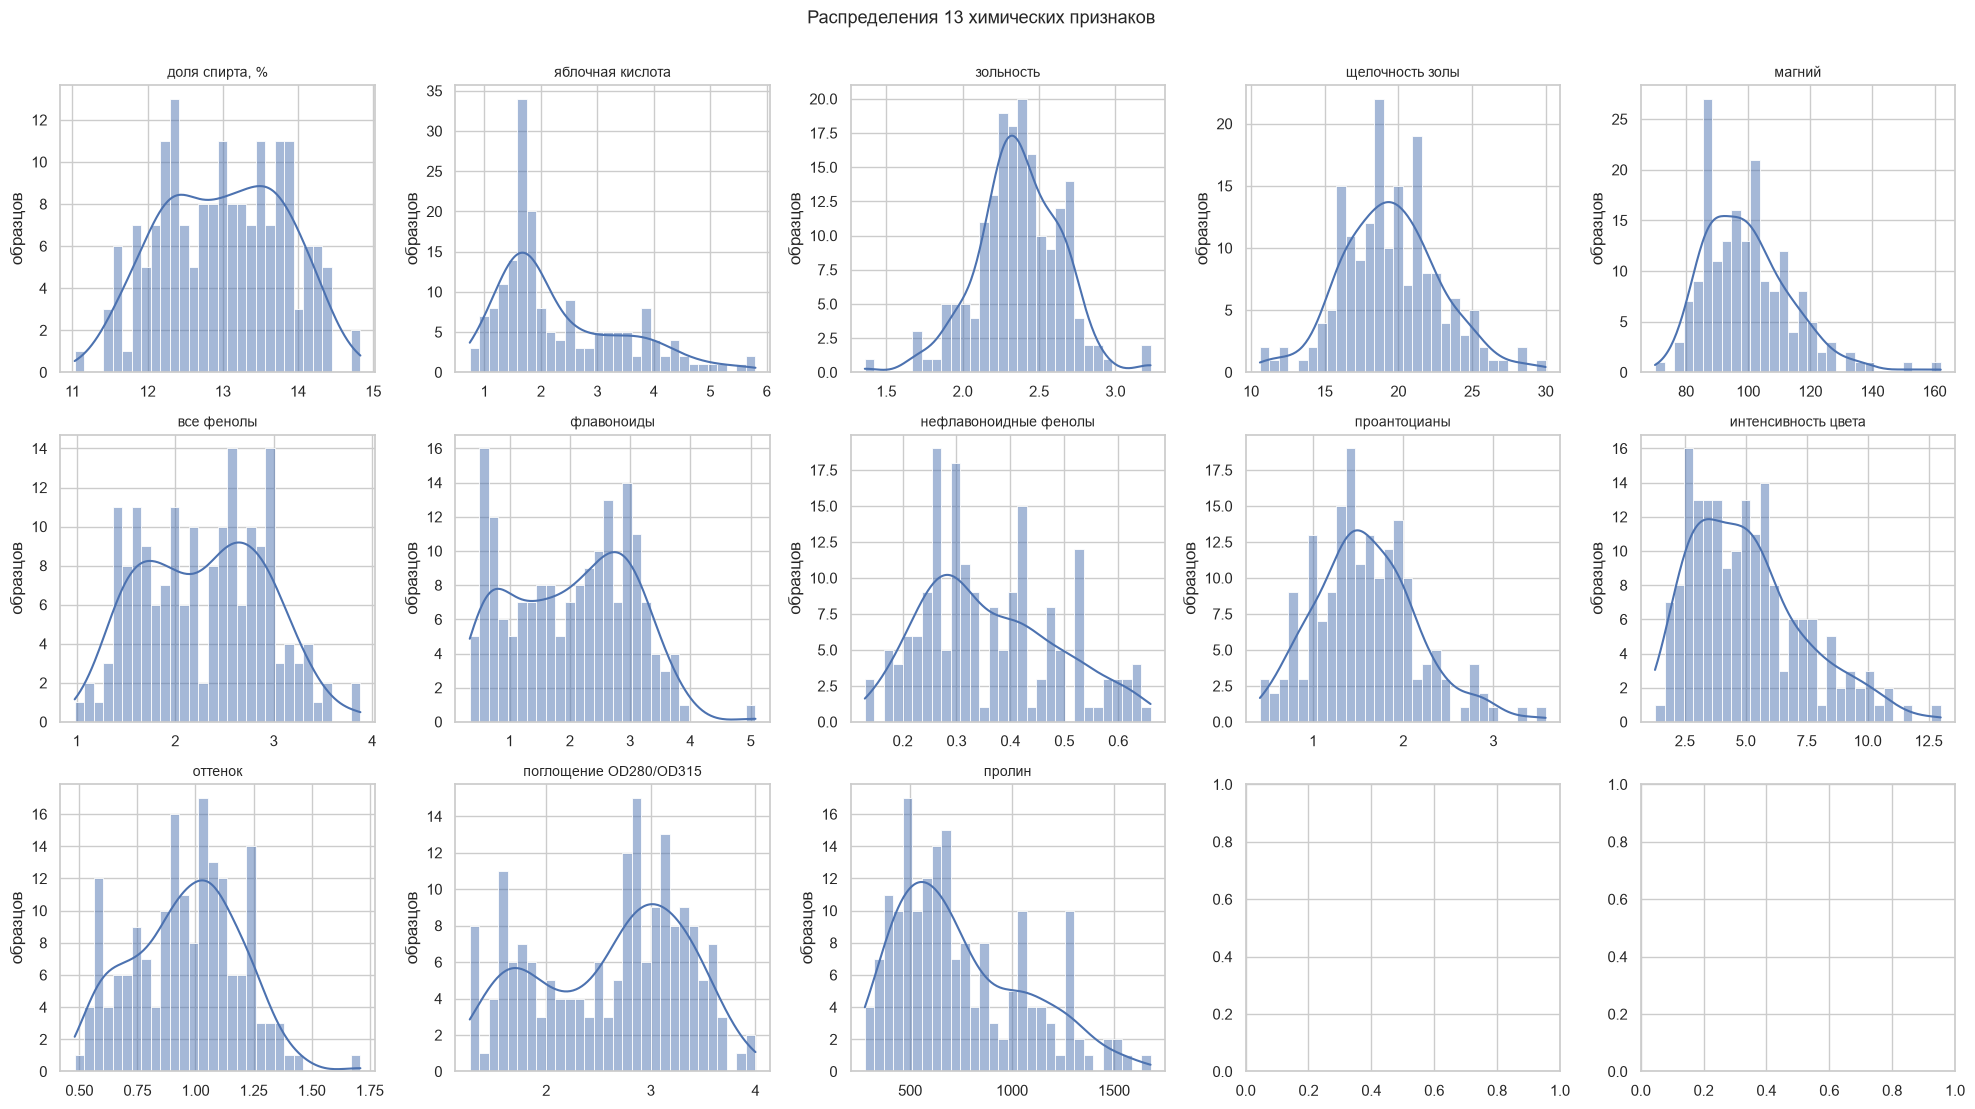

масштабы признаков различаются на два порядка:


,"размах, единиц измерения"
proline,1402.00
magnesium,92.00
alcalinity_of_ash,19.40
color_intensity,11.72
malic_acid,5.06
flavanoids,4.74
alcohol,3.80
proanthocyanins,3.17
total_phenols,2.90
od280/od315_of_diluted_wines,2.73


In [16]:
# 3.1 Распределения числовых признаков.
# Важно смотреть на масштаб, а не на "красивые" гистограммы: у магния
# разброс в сотнях единиц, у нефлавоноидных фенолов - в десятых долях.
figure, axes = plt.subplots(3, 5, figsize=(20, 11))
for axis, column in zip(axes.flat, FEATURE_COLUMNS):
    sns.histplot(data=clean, x=column, kde=True, ax=axis, color="#4C72B0", bins=30)
    axis.set_title(FEATURE_RU[column], fontsize=10)
    axis.set_xlabel("")
    axis.set_ylabel("образцов")
figure.suptitle("Распределения 13 химических признаков", y=1.005)
figure.tight_layout()
plt.show()

print("масштабы признаков различаются на два порядка:")
spread = (clean[FEATURE_COLUMNS].max() - clean[FEATURE_COLUMNS].min()).sort_values(ascending=False)
display(spread.round(2).to_frame("размах, единиц измерения"))


,сорт 0,сорт 1,сорт 2
alcohol,13.74,12.28,13.15
malic_acid,2.01,1.93,3.33
ash,2.46,2.24,2.44
alcalinity_of_ash,17.04,20.24,21.42
magnesium,106.34,94.55,99.31
total_phenols,2.84,2.26,1.68
flavanoids,2.98,2.08,0.78
nonflavanoid_phenols,0.29,0.36,0.45
proanthocyanins,1.90,1.63,1.15
color_intensity,5.53,3.09,7.40


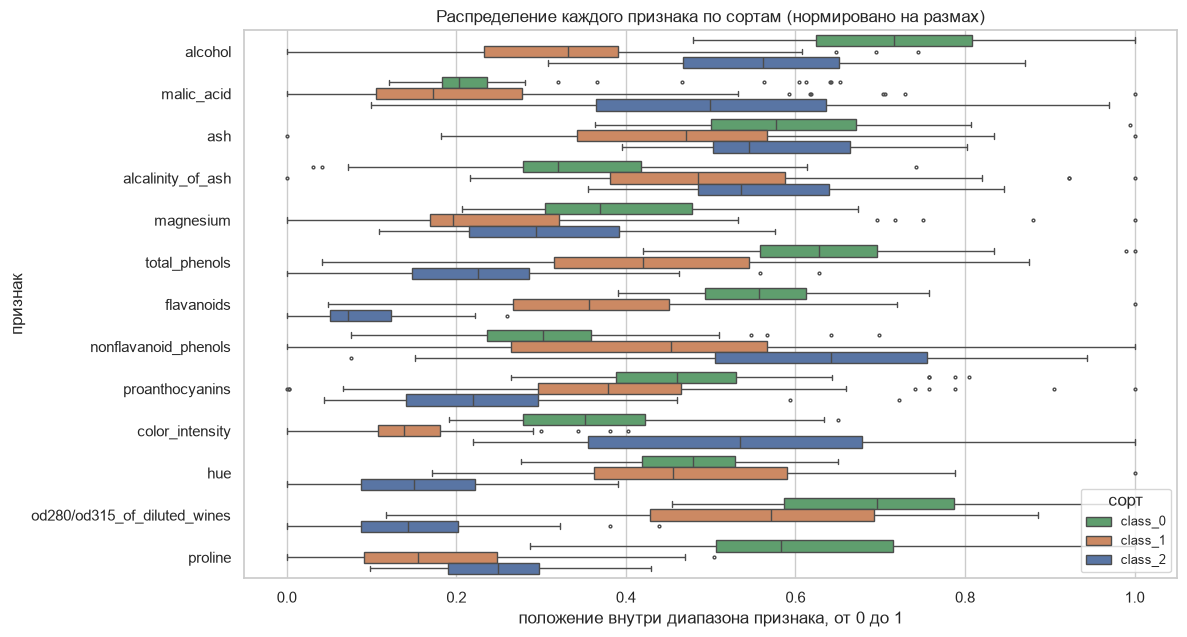

,"разброс между средними сортов, % размаха"
od280/od315_of_diluted_wines,54.0
flavanoids,46.4
proline,42.5
total_phenols,40.0
alcohol,38.6
color_intensity,36.8
hue,30.8
nonflavanoid_phenols,29.7
malic_acid,27.7
proanthocyanins,23.5


In [17]:
# 3.2 Средние значения по сортам - главная таблица разведки.
# Читать по строкам: строка - признак, столбец - сорт.
# Самый резкий контраст у пролина: 1116 / 520 / 630 мг/л.
class_means = clean.groupby(TARGET)[FEATURE_COLUMNS].mean().T
class_means.columns = [CLASS_RU[name] for name in class_means.columns]
display(class_means.round(2))

figure, axis = plt.subplots(figsize=(12, 6.5))
normalized = (clean[FEATURE_COLUMNS] - clean[FEATURE_COLUMNS].min()) / (
    clean[FEATURE_COLUMNS].max() - clean[FEATURE_COLUMNS].min())
melted = normalized.assign(**{TARGET: clean[TARGET].to_numpy()}).melt(
    id_vars=TARGET, var_name="признак", value_name="доля от размаха")

sns.boxplot(data=melted, x="доля от размаха", y="признак", hue=TARGET,
            hue_order=CLASS_NAMES, palette=CLASS_COLORS, ax=axis, fliersize=2)
axis.set_title("Распределение каждого признака по сортам (нормировано на размах)")
axis.set_xlabel("положение внутри диапазона признака, от 0 до 1")
axis.set_ylabel("признак")
axis.legend(title="сорт", fontsize=9, loc="lower right")
figure.tight_layout()
plt.show()

# Разброс между средними считаем в единицах собственного размаха
# признака. Без нормировки пролин всегда был бы первым, даже если
# различал сорта хуже всех, поэтому делим каждый признак на размах.
feature_range = (clean[FEATURE_COLUMNS].max() - clean[FEATURE_COLUMNS].min())
spread_between = ((class_means.max(axis=1) - class_means.min(axis=1)) / feature_range)
spread_between = (100 * spread_between).sort_values(ascending=False)
display(spread_between.round(1).rename("разброс между средними сортов, % размаха").to_frame())


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
alcohol,1.00,0.09,0.21,-0.31,0.27,0.29,0.24,-0.16,0.14,0.55,-0.07,0.07,0.64
malic_acid,0.09,1.00,0.16,0.29,-0.05,-0.34,-0.41,0.29,-0.22,0.25,-0.56,-0.37,-0.19
ash,0.21,0.16,1.00,0.44,0.29,0.13,0.12,0.19,0.01,0.26,-0.07,0.00,0.22
alcalinity_of_ash,-0.31,0.29,0.44,1.00,-0.08,-0.32,-0.35,0.36,-0.20,0.02,-0.27,-0.28,-0.44
magnesium,0.27,-0.05,0.29,-0.08,1.00,0.21,0.20,-0.26,0.24,0.20,0.06,0.07,0.39
total_phenols,0.29,-0.34,0.13,-0.32,0.21,1.00,0.86,-0.45,0.61,-0.06,0.43,0.70,0.50
flavanoids,0.24,-0.41,0.12,-0.35,0.20,0.86,1.00,-0.54,0.65,-0.17,0.54,0.79,0.49
nonflavanoid_phenols,-0.16,0.29,0.19,0.36,-0.26,-0.45,-0.54,1.00,-0.37,0.14,-0.26,-0.50,-0.31
proanthocyanins,0.14,-0.22,0.01,-0.20,0.24,0.61,0.65,-0.37,1.00,-0.03,0.30,0.52,0.33
color_intensity,0.55,0.25,0.26,0.02,0.20,-0.06,-0.17,0.14,-0.03,1.00,-0.52,-0.43,0.32


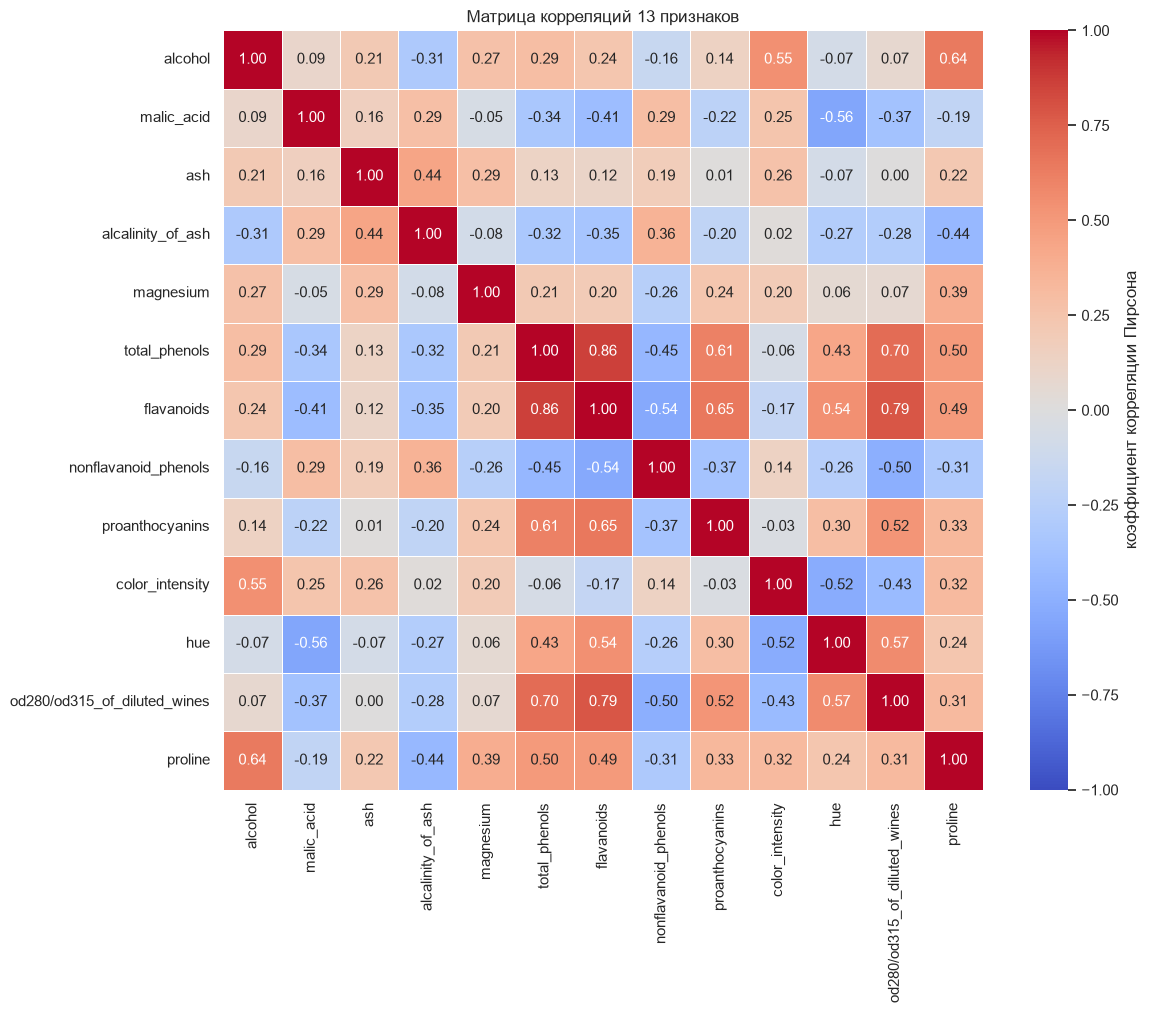

самые сильные положительные связи между признаками:
total_phenols  flavanoids                      0.865
flavanoids     od280/od315_of_diluted_wines    0.787
total_phenols  od280/od315_of_diluted_wines    0.700
flavanoids     proanthocyanins                 0.653

самая сильная отрицательная связь:
malic_acid  hue                    -0.561
flavanoids  nonflavanoid_phenols   -0.538

вывод: flavanoids и total_phenols коррелируют на 0.865 - это почти дубль,
и потому оба в топе важности оказаться не могут (раздел 7.1)


In [18]:
# 3.3 Матрица корреляций. Пирсон ловит только ЛИНЕЙНУЮ связь, а
# дерево ищет правила "признак больше порога". Матрица нужна, чтобы
# быстро найти признаки-дубликаты.
correlation = clean[FEATURE_COLUMNS].corr()

display(correlation.round(2))

figure, axis = plt.subplots(figsize=(12, 10))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, linewidths=0.4, ax=axis,
            cbar_kws={"label": "коэффициент корреляции Пирсона"})
axis.set_title("Матрица корреляций 13 признаков")
figure.tight_layout()
plt.show()

# Самые связанные пары - подозрение на дубликаты. Пара флавоноидов и
# суммарных фенолов разбирается в разделе 7.1.
upper_triangle = correlation.where(np.triu(np.ones(correlation.shape), 1).astype(bool)).stack().dropna()
print("самые сильные положительные связи между признаками:")
print(upper_triangle.sort_values(ascending=False).head(4).round(3).to_string())
print("\nсамая сильная отрицательная связь:")
print(upper_triangle.sort_values().head(2).round(3).to_string())
print("\nвывод: flavanoids и total_phenols коррелируют на {:.3f} - это почти дубль,".format(
    float(correlation.loc["flavanoids", "total_phenols"])))
print("и потому оба в топе важности оказаться не могут (раздел 7.1)")


### 3.4 Где проходит граница между сортами

Вопрос «какой признак различает сорта» в этом наборе имеет неочевидный ответ,
и он важнее любой таблицы корреляций. Для каждой пары сортов и каждого
признака можно проверить: **есть ли между диапазонами зазор, или они
накладываются?**

Если диапазоны накладываются (общая часть непуста), никакой порог по этому
признаку не разделит пару идеально. Если же между ними настоящий зазор, то
одного порога достаточно.

Ниже эта проверка делается кодом для всех 13 признаков и всех 3 пар сортов -
то есть 39 сравнений, а не выборочно.


In [19]:
# Для каждой пары сортов и каждого признака сравниваем диапазоны.
# "ЗАЗОР" - максимум одного сорта меньше минимума другого и порог
# существует; "перекрытие" - обратное.
boundary_rows = []
for first in range(3):
    for second in range(first + 1, 3):
        for column in FEATURE_COLUMNS:
            first_values = clean.loc[clean[TARGET] == CLASS_NAMES[first], column]
            second_values = clean.loc[clean[TARGET] == CLASS_NAMES[second], column]
            low = max(first_values.min(), second_values.min())
            high = min(first_values.max(), second_values.max())
            if high < low:
                boundary_rows.append({
                    "пара сортов": f"{CLASS_NAMES[first]} / {CLASS_NAMES[second]}",
                    "признак": column,
                    "что": "ЗАЗОР",
                    "ширина зазора": round(low - high, 3),
                })
            else:
                boundary_rows.append({
                    "пара сортов": f"{CLASS_NAMES[first]} / {CLASS_NAMES[second]}",
                    "признак": column,
                    "что": "перекрытие",
                    "ширина зазора": 0.0,
                })

boundary = pd.DataFrame(boundary_rows)
gaps = boundary[boundary["что"] == "ЗАЗОР"]

print("пар сортов и признаков проверено:", len(boundary))
print("случаев с настоящим зазором:", len(gaps))
display(gaps)

print("пары сортов и число признаков, где диапазоны накладываются:")
overlaps = (boundary[boundary["что"] == "перекрытие"].groupby("пара сортов")
            .size().rename("признаков с перекрытием").to_frame())
display(overlaps)


пар сортов и признаков проверено: 39
случаев с настоящим зазором: 2


,пара сортов,признак,что,ширина зазора
19,class_0 / class_2,flavanoids,ЗАЗОР,0.62
24,class_0 / class_2,od280/od315_of_diluted_wines,ЗАЗОР,0.04


пары сортов и число признаков, где диапазоны накладываются:


,признаков с перекрытием
пара сортов,
class_0 / class_1,13
class_0 / class_2,11
class_1 / class_2,13


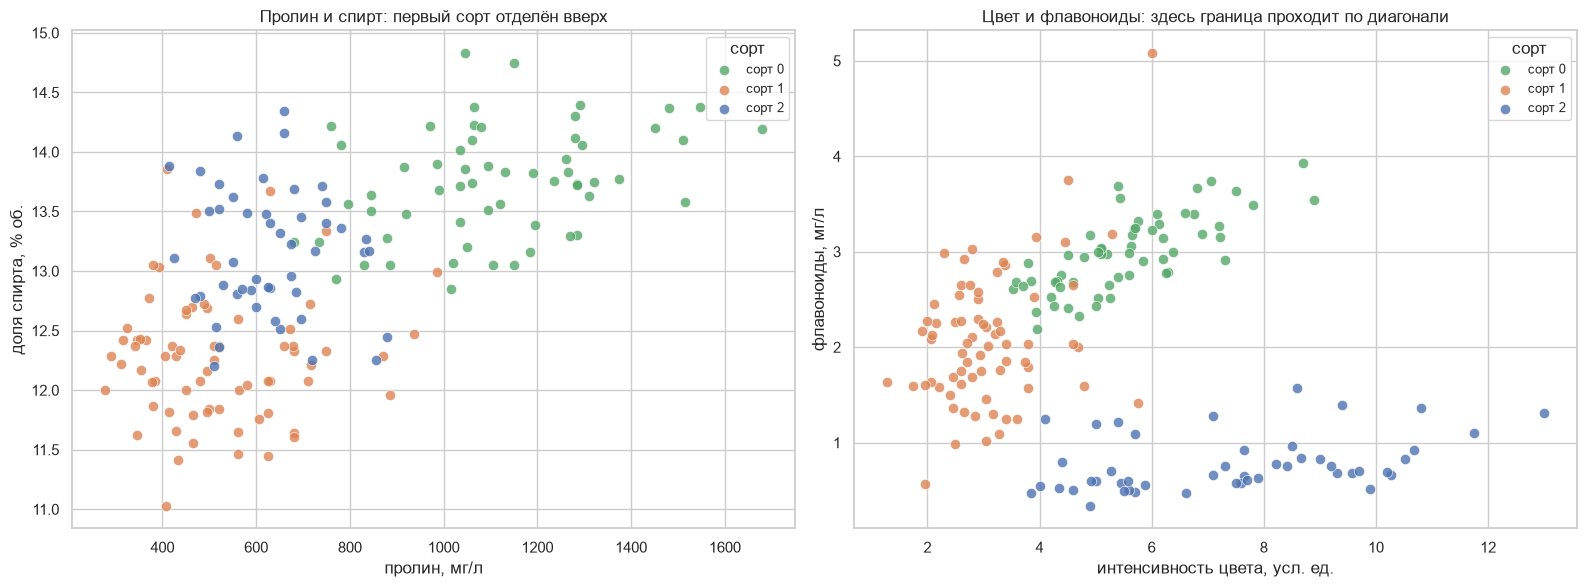

диапазоны флавоноидов по сортам:
          min   max
class              
class_0  2.19  3.93
class_1  0.57  5.08
class_2  0.34  1.57

зазор между class_0 и class_2 по флавоноидам: 0.62 мг/л
порог между ними любой из интервала 1.57 .. 2.19 разделяет эту пару без единой ошибки
по остальным парам и признакам зазора нет ни разу


In [20]:
# Тот же вывод на плоскости двух самых различающих признаков: слева
# пролин против спирта, справа цвет против флавоноидов. Облака первого
# и третьего сорта почти не смыкаются, второе залезает в оба.
figure, axes = plt.subplots(1, 2, figsize=(16, 6))

for name in CLASS_NAMES:
    part = clean[clean[TARGET] == name]
    axes[0].scatter(part["proline"], part["alcohol"], s=55, alpha=0.8,
                    label=CLASS_RU[name], color=CLASS_COLORS[name],
                    edgecolor="white", linewidth=0.5)
    axes[1].scatter(part["color_intensity"], part["flavanoids"], s=55, alpha=0.8,
                    label=CLASS_RU[name], color=CLASS_COLORS[name],
                    edgecolor="white", linewidth=0.5)

axes[0].set_title("Пролин и спирт: первый сорт отделён вверх")
axes[0].set_xlabel("пролин, мг/л")
axes[0].set_ylabel("доля спирта, % об.")
axes[1].set_title("Цвет и флавоноиды: здесь граница проходит по диагонали")
axes[1].set_xlabel("интенсивность цвета, усл. ед.")
axes[1].set_ylabel("флавоноиды, мг/л")
for axis in axes:
    axis.legend(title="сорт", fontsize=9, loc="best")
figure.tight_layout()
plt.show()

# Числом то же самое: где проходит граница, выраженная в зазоре.
flavanoid_ranges = clean.groupby(TARGET)["flavanoids"].agg(["min", "max"])
print("диапазоны флавоноидов по сортам:")
print(flavanoid_ranges.round(2).to_string())

flav_gap = (flavanoid_ranges.loc["class_0", "min"]
            - flavanoid_ranges.loc["class_2", "max"])
print("\nзазор между class_0 и class_2 по флавоноидам: {:.2f} мг/л".format(float(flav_gap)))
print("порог между ними любой из интервала {:.2f} .. {:.2f} разделяет эту пару без единой ошибки".format(
    float(flavanoid_ranges.loc["class_2", "max"]), float(flavanoid_ranges.loc["class_0", "min"])))
print("по остальным парам и признакам зазора нет ни разу")


### 3.5 А честно ли вообще разделить эти сорта

Прежде чем строить модель, стоит проверить, насколько задача трудная сама по
себе. Для этого есть простейший ориентир: **ближайший сосед по всем 13
признакам**. Модель не обучается вообще - она просто находит самый похожий
образец и называет его сорт.

Проверка идёт по правилу **leave-one-out**: для каждого образца сосед ищется
по всем остальным 177. Никаких выборок и никакого подглядывания - это чистая
мера разделимости данных, а не модель, которую можно переобучить.

Если даже этот примитив ошибается часто, то высокая точность леса будет
реальным результатом. Если бы он ошибался редко, это тоже надо сказать вслух:
значит, данные настолько просты, что справится любой алгоритм.


In [21]:
# Ближайший сосед по leave-one-out: ищем двух ближайших, первый - он
# сам, второй и есть его сосед по остальным образцам.
neighbour_model = NearestNeighbors(n_neighbors=2).fit(clean[FEATURE_COLUMNS].to_numpy())
_, neighbour_index = neighbour_model.kneighbors(
    clean[FEATURE_COLUMNS].to_numpy(), n_neighbors=2)
neighbour_prediction = clean[TARGET].to_numpy()[neighbour_index[:, 1]]

difficulty_wrong = neighbour_prediction != clean[TARGET].to_numpy()
difficulty_accuracy = 1 - difficulty_wrong.mean()

print("accuracy ближайшего соседа (leave-one-out): {:.4f}".format(float(difficulty_accuracy)))
print("ошибок соседа leave-one-out: {} из {}".format(int(difficulty_wrong.sum()), len(clean)))

print("\nошибки соседа по сортам:")
print(clean.loc[difficulty_wrong, TARGET].value_counts().reindex(CLASS_NAMES).to_string())
print("\nошибки соседа по парам сортов:")
pairs = pd.DataFrame({"истинный": clean[TARGET].to_numpy()[difficulty_wrong],
                      "предсказан": neighbour_prediction[difficulty_wrong]})
pairs["пара"] = pairs["истинный"] + " -> " + pairs["предсказан"]
display(pairs["пара"].value_counts().rename("ошибок").to_frame())
print("\nвывод: даже модель без единого параметра справляется не идеально,")
print("значит, различение сортов - настоящая задача, а не формальность.")


accuracy ближайшего соседа (leave-one-out): 0.7697
ошибок соседа leave-one-out: 41 из 178

ошибки соседа по сортам:
class
class_0     7
class_1    17
class_2    17

ошибки соседа по парам сортов:


,ошибок
пара,
class_2 -> class_1,14
class_1 -> class_2,12
class_1 -> class_0,5
class_0 -> class_2,4
class_0 -> class_1,3
class_2 -> class_0,3



вывод: даже модель без единого параметра справляется не идеально,
значит, различение сортов - настоящая задача, а не формальность.


## 4. Подготовка данных

### 4.1 Что нужно сделать и что не нужно

**Кодировать нечего.** Все 13 признаков числовые, категориальных столбцов в
наборе нет. Проверка типов в разделе 1 это уже показала.

**Масштабировать тоже не нужно.** Дерево решений сравнивает значение с порогом
и от единиц измерения не зависит: условие `proline <= 985` работает одинаково
независимо от того, в каких единицах измерен пролин, а прибавление к обоим
концам условия одного и того же числа не меняет ни одного разбиения. (А вот
для линейной модели и для нейросети здесь масштабирование обязательно: там
складываются веса, и единицы измерения имеют значение.)

### 4.2 Как делить выборку

Выборок три:

* **обучающая** - на ней строится лес;
* **валидационная** - на ней перебираются гиперпараметры;
* **тестовая** - трогается один раз, в разделе оценки, и больше нигде.

Разбиение **стратифицированное**: в каждой части сохраняются пропорции сортов.
На 178 строках и трёх классах это не формальность. Ниже это показано замером -
одно и то же зерно, но со стратификацией и без неё, и двадцать случайных
разбиений.


In [22]:
# Матрица признаков и целевая переменная. Метку оставляем строкой:
# sklearn сам кодирует метки, зато в отчётах остаются названия сортов.
X = clean[FEATURE_COLUMNS]
y = clean[TARGET]

# Основное разбиение 60 / 20 / 20 со стратификацией и фиксированным
# зерном. Второй шаг берёт половину от промежуточной части.
X_train, X_rest, y_train, y_rest = train_test_split(
    X, y, test_size=0.40, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.50, random_state=SEED, stratify=y_rest)

split_table = pd.DataFrame({
    "выборка": ["обучающая", "валидационная", "тестовая"],
    "строк": [len(X_train), len(X_val), len(X_test)],
})
for name in CLASS_NAMES:
    split_table[name] = [
        int((y_train == name).sum()),
        int((y_val == name).sum()),
        int((y_test == name).sum()),
    ]
split_table = split_table.set_index("выборка")
display(split_table)

print("строк в обучающей выборке:", len(X_train))
print("строк в валидационной выборке:", len(X_val))
print("строк в тестовой выборке:", len(X_test))
print("одна ошибка на тесте стоит {:.2f} п.п. точности".format(100 / len(y_test)))
print("доли сортов в train:", y_train.value_counts(normalize=True).round(3).to_dict())
print("доли сортов в test: ", y_test.value_counts(normalize=True).round(3).to_dict())
print("индексы строк не пересекаются:",
      len(set(X_train.index) & set(X_val.index)),
      len(set(X_train.index) & set(X_test.index)),
      len(set(X_val.index) & set(X_test.index)))


,строк,class_0,class_1,class_2
выборка,,,,
обучающая,106,35,42,29
валидационная,36,12,14,10
тестовая,36,12,15,9


строк в обучающей выборке: 106
строк в валидационной выборке: 36
строк в тестовой выборке: 36
одна ошибка на тесте стоит 2.78 п.п. точности
доли сортов в train: {'class_1': 0.396, 'class_0': 0.33, 'class_2': 0.274}
доли сортов в test:  {'class_1': 0.417, 'class_0': 0.333, 'class_2': 0.25}
индексы строк не пересекаются: 0 0 0


In [23]:
# Зачем нужна стратификация, проверяем числом: смещение пропорций на
# 2-3 образца - это уже 6-8 п.п. точности, то есть артефакт разбиения.
_, plain_rest, _, plain_rest_y = train_test_split(X, y, test_size=0.40, random_state=SEED)
_, _, _, plain_test_y = train_test_split(plain_rest, plain_rest_y,
                                        test_size=0.50, random_state=SEED)

print("то же зерно генератора, но без стратификации:")
print("  доля class_2 в тесте: {:.3f}".format(float((plain_test_y == "class_2").mean())))
print("то же зерно генератора, со стратификацией:")
print("  доля class_2 в тесте: {:.3f}".format(float((y_test == "class_2").mean())))
print("\nбез стратификации тест решает другую задачу - там может оказаться")
print("другое число образцов class_2, и сравнивать модели бессмысленно.")

# Насколько сильно плавает состав теста в двадцати случайных разбиениях.
plain_counts, stratified_counts = [], []
for seed in range(20):
    _, _, _, plain_target = train_test_split(X, y, test_size=0.20, random_state=seed)
    plain_counts.append(int((plain_target == "class_2").sum()))
    _, _, _, layered_target = train_test_split(X, y, test_size=0.20,
                                               random_state=seed, stratify=y)
    stratified_counts.append(int((layered_target == "class_2").sum()))

print("\nв 20 разбиениях без стратификации число class_2 в тесте: от",
      min(plain_counts), "до", max(plain_counts))
print("в тех же 20 разбиениях со стратификацией:", sorted(set(stratified_counts)))
print("ДИАПАЗОН БЕЗ СТРАТИФИКАЦИИ: {} .. {}".format(min(plain_counts), max(plain_counts)))
print("ДИАПАЗОН СО СТРАТИФИКАЦИЕЙ: {} .. {}".format(min(stratified_counts), max(stratified_counts)))
print("\nвывод: стратификация не косметика - без неё тестовая выборка просто")
print("перестаёт быть тем же самым набором образцов, и сравнивать модели нельзя.")


то же зерно генератора, но без стратификации:
  доля class_2 в тесте: 0.194
то же зерно генератора, со стратификацией:
  доля class_2 в тесте: 0.250

без стратификации тест решает другую задачу - там может оказаться
другое число образцов class_2, и сравнивать модели бессмысленно.



в 20 разбиениях без стратификации число class_2 в тесте: от 5 до 16
в тех же 20 разбиениях со стратификацией: [10]
ДИАПАЗОН БЕЗ СТРАТИФИКАЦИИ: 5 .. 16
ДИАПАЗОН СО СТРАТИФИКАЦИЕЙ: 10 .. 10

вывод: стратификация не косметика - без неё тестовая выборка просто
перестаёт быть тем же самым набором образцов, и сравнивать модели нельзя.


## 5. Модель: случайный лес

### 5.1 Как устроен алгоритм

Случайный лес - ансамбль из многих деревьев решений, и каждый шаг нужен не
сам по себе, а ради одного эффекта. Разбираем по порядку.

**1. Бутстрэп - случайные строки.** Для каждого дерева из обучающей выборки
берётся свой случайный набор строк **с повторениями**: одна строка может
попасть в три дерева, а другая - ни в одно. Деревья получаются разными
неизбежно, и это уже половина смысла.

**2. Случайные признаки.** При каждом разбиении узла перебираются не все 13
признаков, а случайная выборка из `max_features`. Это защита от второй
разновидности переобучения: одного глубокого дерева неполного - «слабого
предсказателя», который нельзя усреднять, потому что он переобучен на
собственных строках.

**3. Независимость.** Деревья строятся **друг от друга не зависимо**, поэтому
лес обучается параллельно (`n_jobs=-1`) и не деградирует от числа деревьев.

**4. Голосование.** Каждое дерево выдаёт свой сорт. Итоговый ответ - сорт, за
который проголосовало большинство деревьев; в `RandomForestClassifier` это то
же самое, что максимум средней вероятности по трёмстам деревьям.

**Ключевая идея - почему это работает.** Ошибки отдельных деревьев слабо
коррелируют: дерево, переобученное на одной случайной подвыборке, ошибается
на других точках. Усредняя голоса, лес **гасит эти взаимно не связанные
ошибки** и оставляет ту часть сигнала, которая устойчива. Отсюда же видно, чем
лес лучше одиночного дерева: не обязательно средней точностью, а
**устойчивостью** - результат слабо зависит от того, какое дерево выпало
первым.

Но верно это только тогда, когда деревья переобучаются **по-разному**: если
все они ошибаются в одном и том же месте, усреднение не гасит ничего, а только
размывает найденную границу. Пункт проверяется замером в разделе 6.5, и
проверка даёт результат, которого никто не ожидал: на этом датасете лес не
выигрывает у одного дерева ни по точности, ни по устойчивости. Работа
посвящает этому отдельный раздел вместо того, чтобы обойти молчанием.

### 5.2 Параметры, зафиксированные в работе

| Параметр | Значение | Почему |
|---|---|---|
| `n_estimators` | **подбирается на валидации** | число деревьев; это «ёмкость» леса, напрямую влияет на качество |
| `random_state` | **SEED = 42** | фиксирует случайный выбор строк и признаков |
| `n_jobs` | **-1** | обучение деревьев параллельно на всех ядрах CPU |
| `max_features` | **подбирается на валидации** | сколько признаков пробовать в каждом разбиении; главный «рычаг» качества |
| `max_depth` | **подбирается на валидации** | ограничение глубины; в лесу обычно лучше не ограничивать |
| `min_samples_leaf` | **подбирается на валидации** | минимальный размер листа; регулирует гладкость модели |
| `class_weight` | не используется | перекос классов 1,48 к 1 слишком мал, чтобы перевешивать веса |

Подбор гиперпараметров идёт **только по валидационной выборке**. Тестовая
выборка в подборе не участвует ни разу.


In [24]:
def build_forest(n_estimators=N_ESTIMATORS, n_jobs=N_JOBS, random_state=SEED, **hyperparameters):
    """Собирает случайный лес для классификации с настройками всей работы.

    max_features - сколько признаков пробовать в каждом разбиении
        ("sqrt", доля от 1 или целое число);
    max_depth - ограничение глубины дерева (None - без ограничения);
    min_samples_leaf - минимальное число образцов в листе.
    """
    return RandomForestClassifier(
        n_estimators=n_estimators,
        random_state=random_state,   # без него лес каждый раз был бы немного другим
        n_jobs=n_jobs,               # деревья независимы, считаем их параллельно
        **hyperparameters,
    )


print(build_forest())
print()
print("поддерживаемые значения: max_features = 'sqrt' или доля от 1,")
print("max_depth = None (без ограничения), min_samples_leaf = 1 (лист из одного образца)")


RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42)

поддерживаемые значения: max_features = 'sqrt' или доля от 1,
max_depth = None (без ограничения), min_samples_leaf = 1 (лист из одного образца)


## 6. Обучение и подбор гиперпараметров

### 6.1 Базовая линия

Метрика ничего не доказывает, пока не с чем её сравнить. Базовая линия здесь -
`DummyClassifier`: модель, которая **смотрит на все признаки, а предсказывает
самый частый сорт** (`class_1`, 71 образец из 178). Без неё результат
бессмысленен.


In [25]:
# Базовая линия: игнорируем признаки, всегда называем самый частый сорт.
baseline = DummyClassifier(strategy="most_frequent", random_state=SEED)
baseline.fit(X_train, y_train)

baseline_prediction = baseline.predict(X_test)
print("сорт, который всегда предсказывает базовая линия:", baseline.predict(X_test)[0])
print("вероятности базовой линии для одной строки:",
      np.round(baseline.predict_proba(X_test[:1])[0], 3).tolist())
print("accuracy базовой линии на тесте: {:.4f}".format(
    accuracy_score(y_test, baseline_prediction)))
print("\nтакая модель не смотрит ни на спирт, ни на флавоноиды - она заведомо")
print("слабее леса, и именно с ней нужно сравнивать.")


сорт, который всегда предсказывает базовая линия: class_1
вероятности базовой линии для одной строки: [0.0, 1.0, 0.0]
accuracy базовой линии на тесте: 0.4167

такая модель не смотрит ни на спирт, ни на флавоноиды - она заведомо
слабее леса, и именно с ней нужно сравнивать.


In [26]:
# Первое обучение с параметрами по умолчанию - точка отсчёта, чтобы
# было видно, даёт ли подбор вообще что-нибудь.
base_model = build_forest()
base_model.fit(X_train, y_train)

print("accuracy по умолчанию на train:", round(base_model.score(X_train, y_train), 4))
print("accuracy по умолчанию на val:  ", round(base_model.score(X_val, y_val), 4))
print("accuracy базовой линии на val:", round(baseline.score(X_val, y_val), 4))
print("\nошибок на обучении:", int((base_model.predict(X_train) != y_train.to_numpy()).sum()),
      "из", len(X_train))


accuracy по умолчанию на train: 1.0
accuracy по умолчанию на val:   0.9722
accuracy базовой линии на val: 0.3889

ошибок на обучении: 0 из 106


### 6.2 Подбор `max_features`, `max_depth`, `min_samples_leaf`

Перебираем восемь конфигураций и смотрим точность **только на валидации**.
Тестовая выборка в переборе не участвует ни разу: подбирать параметры по
тесту - значит подбирать их под ответ.

Список составлен **от более ограниченной конфигурации к более свободной**.
Это не украшение, а правило разрешения ничьих: на маленькой выборке почти все
разумные конфигурации дают одинаковую точность (в этом можно убедиться в
таблице ниже), и выбирать из них надо самую регуляризованную - ту, которая
хуже всего переобучается. Поэтому при равенстве побеждает первая строка списка.


In [27]:
# Сетка подбора. Все три настраиваемых параметра указаны в каждом
# варианте явно, чтобы не спутать "не задано" с "забыли проверить".
CANDIDATES = {
    "sqrt признаков, глубина 3": dict(max_features="sqrt", max_depth=3, min_samples_leaf=1),
    "sqrt признаков, лист >= 2": dict(max_features="sqrt", max_depth=None, min_samples_leaf=2),
    "sqrt признаков, без ограничений": dict(max_features="sqrt", max_depth=None, min_samples_leaf=1),
    "sqrt признаков, глубина 5": dict(max_features="sqrt", max_depth=5, min_samples_leaf=1),
    "половина признаков, без ограничений": dict(max_features=0.5, max_depth=None, min_samples_leaf=1),
    "70% признаков, без ограничений": dict(max_features=0.7, max_depth=None, min_samples_leaf=1),
    "все 13 признаков, без ограничений": dict(max_features=1.0, max_depth=None, min_samples_leaf=1),
    "все 13 признаков, лист >= 3": dict(max_features=1.0, max_depth=None, min_samples_leaf=3),
}

validation_rows = []
for label, options in CANDIDATES.items():
    candidate = build_forest(**options).fit(X_train, y_train)
    prediction = candidate.predict(X_val)
    validation_rows.append({
        "вариант": label,
        "accuracy_val": round(candidate.score(X_val, y_val), 4),
        "F1_val": round(f1_score(y_val, prediction, average=AVERAGE, zero_division=0), 4),
        **options,
    })

validation_table = pd.DataFrame(validation_rows)
display(validation_table)

# Выбираем по максимуму точности на валидации; при равенстве побеждает
# первая строка списка (stable-сортировка), то есть самая регуляризованная.
best_row = validation_table.sort_values("accuracy_val", ascending=False,
                                        kind="stable").iloc[0]
best_label = best_row["вариант"]
best_params = CANDIDATES[best_label]
best_val_accuracy = float(best_row["accuracy_val"])

# Насколько конфигурации различимы: переводим разницу в число ошибок
# на валидации.
grid_tie_errors = int(round((validation_table["accuracy_val"].max()
                             - validation_table["accuracy_val"].min()) * len(y_val)))

print("Лучший вариант по валидации:", best_label,
      "(accuracy = {:.4f})".format(best_val_accuracy))
print("Выбранные по валидации параметры:", best_params)
print("разница между лучшим и худшим вариантом: {} ошибок из {}".format(
    grid_tie_errors, len(y_val)))
print("Тестовая выборка в этом подборе не участвовала ни разу.")


,вариант,accuracy_val,F1_val,max_features,max_depth,min_samples_leaf
0,"sqrt признаков, глубина 3",0.9722,0.9743,sqrt,3.0,1
1,"sqrt признаков, лист >= 2",0.9722,0.9743,sqrt,NaN,2
2,"sqrt признаков, без ограничений",0.9722,0.9743,sqrt,NaN,1
3,"sqrt признаков, глубина 5",0.9722,0.9743,sqrt,5.0,1
4,"половина признаков, без ограничений",0.9722,0.9743,0.5,NaN,1
5,"70 % признаков, без ограничений",0.9722,0.9743,0.7,NaN,1
6,"все 13 признаков, без ограничений",0.9722,0.9743,1.0,NaN,1
7,"все 13 признаков, лист >= 3",0.9167,0.9202,1.0,NaN,3


Лучший вариант по валидации: sqrt признаков, глубина 3 (accuracy = 0.9722)
Выбранные по валидации параметры: {'max_features': 'sqrt', 'max_depth': 3, 'min_samples_leaf': 1}
разница между лучшим и худшим вариантом: 2 ошибок из 36
Тестовая выборка в этом подборе не участвовала ни разу.


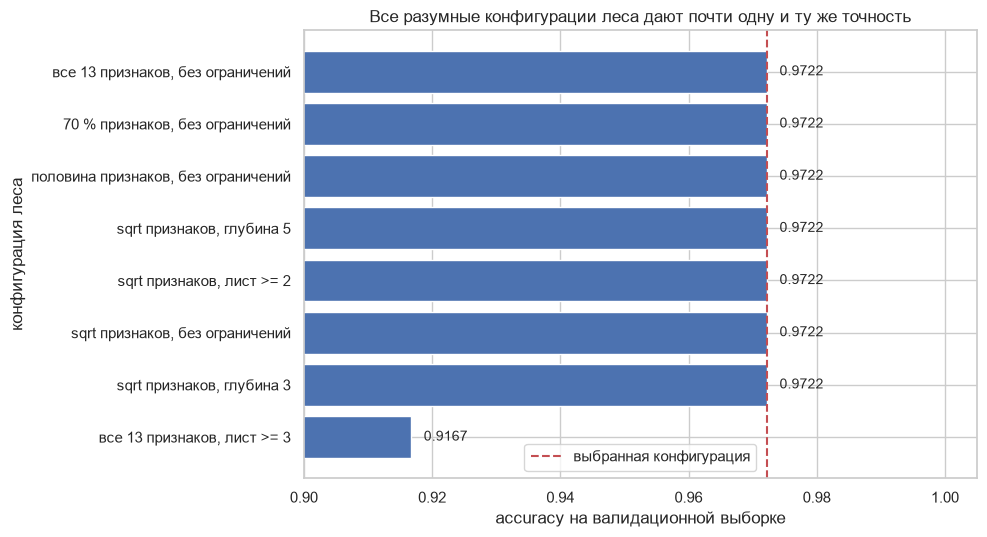

разброс по валидации: от 0.9167 до 0.9722
разница между худшим и лучшим вариантом: 2 ошибок из 36
вывод: на 36 образцах валидации параметры леса неразличимы, поэтому
выбор сделан по правилу наименьшей регуляризованности, а не по числу


In [28]:
# График подбора: разброс между вариантами почти нулевой. max_features,
# max_depth и min_samples_leaf почти не влияют на ответ, и выиграть
# подбором нельзя. Значит, честность оценки обеспечивается не удачным
# подбором, а тем, что тест вообще не участвовал в выборе.
figure, axis = plt.subplots(figsize=(10, 5.5))
plot_table = validation_table.sort_values("accuracy_val", ascending=True)
bars = axis.barh(plot_table["вариант"], plot_table["accuracy_val"], color="#4C72B0")
axis.axvline(best_val_accuracy, color="#C44E52", linestyle="--", linewidth=1.5,
             label="выбранная конфигурация")
axis.set_xlim(0.90, 1.005)
axis.set_xlabel("accuracy на валидационной выборке")
axis.set_ylabel("конфигурация леса")
axis.set_title("Все разумные конфигурации леса дают почти одну и ту же точность")
axis.legend()
for bar, value in zip(bars, plot_table["accuracy_val"]):
    axis.text(value + 0.002, bar.get_y() + bar.get_height() / 2, f"{value:.4f}",
              va="center", fontsize=10)
figure.tight_layout()
plt.show()

print("разброс по валидации: от {:.4f} до {:.4f}".format(
    validation_table["accuracy_val"].min(), validation_table["accuracy_val"].max()))
print("разница между худшим и лучшим вариантом: {} ошибок из {}".format(
    grid_tie_errors, len(y_val)))
print("вывод: на 36 образцах валидации параметры леса неразличимы, поэтому")
print("выбор сделан по правилу наименьшей регуляризованности, а не по числу")


### 6.3 Кросс-валидация: проверка выбора на всей обучающей части

Валидация - это 36 образцов, и разница между вариантами сетки равна буквально
одной-двум ошибкам. На таком размере легко выбрать случайно удачную
конфигурацию. Поэтому тот же перебор повторяется **5-фолдовой стратифицированной
кросс-валидацией** на всей обучающей части (106 образцов, каждый образец
побывает и в обучении, и в проверке).

Кросс-валидация даёт не одну точку, а среднее и **разброс** по пяти фолдам.
Именно разброс показывает, насколько выбранная точность вообще надёжна: если
среднее 0,98, а разброс 0,05, то честно говорить можно только об одном -
«где-то между 0,93 и 1,00».

Тестовая выборка в кросс-валидации по-прежнему не участвует.


,среднее,разброс,худший_fold
вариант,,,
"sqrt признаков, глубина 3",0.9810,0.0233,0.9524
"sqrt признаков, лист >= 2",0.9810,0.0233,0.9524
"sqrt признаков, без ограничений",0.9810,0.0233,0.9524
"sqrt признаков, глубина 5",0.9810,0.0233,0.9524
"половина признаков, без ограничений",0.9810,0.0233,0.9524
"70 % признаков, без ограничений",0.9714,0.0233,0.9524
"все 13 признаков, без ограничений",0.9714,0.0233,0.9524
"все 13 признаков, лист >= 3",0.9619,0.0190,0.9524


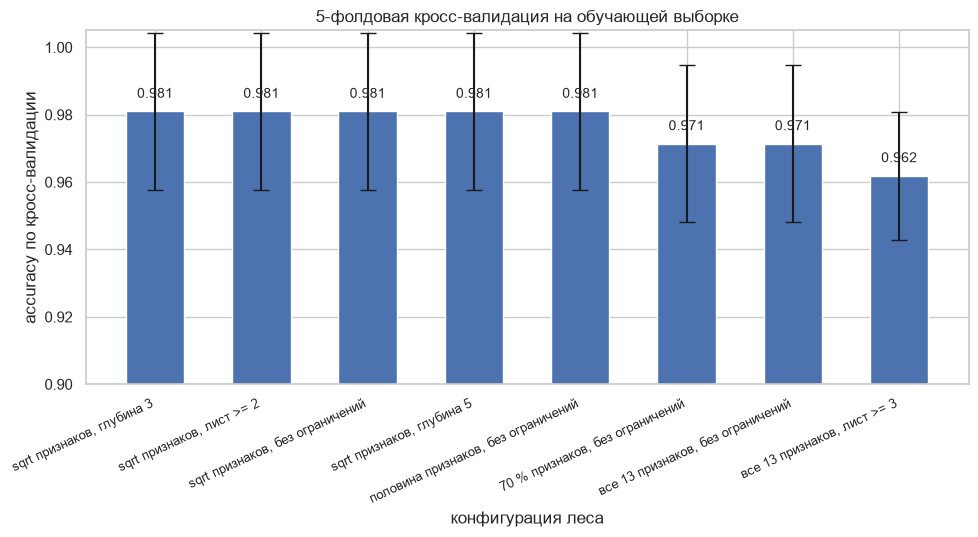

5-фолдовая CV рабочей модели: 0.9810
разброс по фолдам рабочей модели: 0.0233
accuracy рабочей модели на валидации: 0.9722

разброс 0.0233 означает плюс-минус 5 п.п. - это честная граница, внутри
которой все конфигурации сетки неразличимы, и выбирать по ним можно только
условно - поэтому выбор делался по правилу, а не по числу


In [29]:
# Кросс-валидация считается только на train: валидация и тест не участвуют.
cross_validator = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

cv_rows = []
for label, options in CANDIDATES.items():
    folds = cross_val_score(build_forest(**options), X_train, y_train,
                            cv=cross_validator, scoring="accuracy")
    cv_rows.append({
        "вариант": label,
        "среднее": round(float(folds.mean()), 4),
        "разброс": round(float(folds.std()), 4),
        "худший_fold": round(float(folds.min()), 4),
    })

cv_table = pd.DataFrame(cv_rows).sort_values("среднее", ascending=False).set_index("вариант")
display(cv_table)

figure, axis = plt.subplots(figsize=(10, 5.5))
positions = np.arange(len(cv_table))
axis.bar(positions, cv_table["среднее"], 0.55, color="#4C72B0",
         yerr=cv_table["разброс"], capsize=6)
axis.set_xticks(positions)
axis.set_xticklabels(cv_table.index, rotation=25, ha="right", fontsize=9)
axis.set_ylim(0.90, 1.005)
axis.set_xlabel("конфигурация леса")
axis.set_ylabel("accuracy по кросс-валидации")
axis.set_title("5-фолдовая кросс-валидация на обучающей выборке")
for index, value in enumerate(cv_table["среднее"]):
    axis.text(index, value + 0.004, f"{value:.3f}", ha="center", fontsize=10)
figure.tight_layout()
plt.show()

working_folds = cross_val_score(build_forest(**best_params), X_train, y_train,
                                cv=cross_validator, scoring="accuracy")
cv_mean = float(working_folds.mean())
cv_std = float(working_folds.std())

print("5-фолдовая CV рабочей модели: {:.4f}".format(cv_mean))
print("разброс по фолдам рабочей модели: {:.4f}".format(cv_std))
print("accuracy рабочей модели на валидации: {:.4f}".format(best_val_accuracy))
print("\nразброс {:.4f} означает плюс-минус {} п.п. - это честная граница, внутри".format(
    cv_std, round(200 * cv_std)))
print("которой все конфигурации сетки неразличимы, и выбирать по ним можно только")
print("условно - поэтому выбор делался по правилу, а не по числу")


### 6.4 Сколько деревьев нужно лесу

`n_estimators` - единственный параметр, который меняет не форму модели, а её
**объём**: каждое дерево голосует, и число голосов определяет, насколько
сильно усреднение гасит ошибки отдельных деревьев. Это стоит измерить
отдельно, и это же самая прямая демонстрация того, что делает бэггинг.


,деревьев,accuracy_val,accuracy_train
0,1,0.8889,0.9151
1,2,0.8889,0.9057
2,3,0.9444,0.9717
3,5,0.9444,0.9906
4,10,0.9444,1.0000
5,15,0.9722,1.0000
6,25,0.9722,1.0000
7,50,0.9722,1.0000
8,100,0.9722,1.0000
9,200,0.9722,1.0000


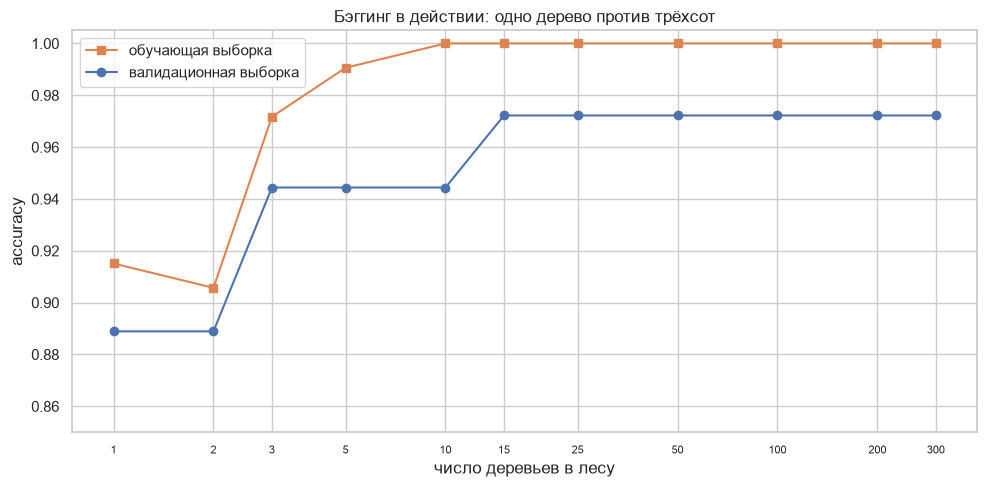

accuracy леса из одного дерева на валидации: 0.8889
accuracy леса из 300 деревьев на валидации: 0.9722
выигрыш бэггинга на валидации: +0.0833
деревьев, после которых точность перестаёт расти: 15

кривая почти не идёт вниз и упирается в потолок - на этом наборе
нельзя переобучить лес увеличением числа деревьев


In [30]:
# Кривая числа деревьев. Первое дерево - обычное дерево решений со
# случайным набором признаков, каждое следующее - ещё один независимый
# голос. Ось x логарифмическая, иначе числа 1..300 слились бы в точку.
trees_counts = [1, 2, 3, 5, 10, 15, 25, 50, 100, 200, N_ESTIMATORS]
tree_curve = []

for count in trees_counts:
    model = build_forest(n_estimators=count).fit(X_train, y_train)
    tree_curve.append({
        "деревьев": count,
        "accuracy_val": round(model.score(X_val, y_val), 4),
        "accuracy_train": round(model.score(X_train, y_train), 4),
    })

tree_curve = pd.DataFrame(tree_curve)
display(tree_curve)

figure, axis = plt.subplots(figsize=(10, 5))
axis.plot(tree_curve["деревьев"], tree_curve["accuracy_train"],
          marker="s", color="#DD8452", label="обучающая выборка")
axis.plot(tree_curve["деревьев"], tree_curve["accuracy_val"],
          marker="o", color="#4C72B0", label="валидационная выборка")
axis.set_xscale("log")
axis.set_xticks(trees_counts)
axis.set_xticklabels([str(count) for count in trees_counts], fontsize=8)
axis.set_ylim(0.85, 1.005)
axis.set_xlabel("число деревьев в лесу")
axis.set_ylabel("accuracy")
axis.set_title("Бэггинг в действии: одно дерево против трёхсот")
axis.legend()
figure.tight_layout()
plt.show()

single_tree_val = float(tree_curve.loc[0, "accuracy_val"])
full_forest_val = float(tree_curve.loc[len(tree_curve) - 1, "accuracy_val"])
plateau_trees = int(tree_curve.loc[tree_curve["accuracy_val"] >= full_forest_val, "деревьев"].min())

print("accuracy леса из одного дерева на валидации: {:.4f}".format(single_tree_val))
print("accuracy леса из {} деревьев на валидации: {:.4f}".format(N_ESTIMATORS, full_forest_val))
print("выигрыш бэггинга на валидации: {:+.4f}".format(full_forest_val - single_tree_val))
print("деревьев, после которых точность перестаёт расти: {}".format(plateau_trees))
print("\nкривая почти не идёт вниз и упирается в потолок - на этом наборе")
print("нельзя переобучить лес увеличением числа деревьев")


### 6.5 Одно дерево против леса: где бэггинг выигрывает

Внутри леса уже есть одиночное дерево, поэтому сравнение не требует ничего,
кроме честности в оценке. Сравниваются **три** модели, а не две:

1. **одиночное дерево** - то, что лес построил бы, если бы деревьев было одно;
2. **лес с выбранными параметрами** (`max_features="sqrt"`, `max_depth=3`) -
   рабочая модель работы;
3. **лес без ограничений** (`max_features=1.0`, без предела глубины) -
   «классический» лес, каким его обычно представляют.

Второй и третий нужны для того, чтобы проверить **механизм** бэггинга.
Разнообразие деревьев само по себе ещё ни о чём не говорит: важно, чтобы
ошибки деревьев не повторялись. Если все 300 деревьев ошибаются в одной и той
же точке границы, усреднение не гасит ничего, а наоборот размывает найденный
порог.

Сравнение делается **двумя способами**. Первый - одно зерно, это один
случайный результат. Второй - **сорок зёрен**: тот же эксперимент,
повторённый сорок раз. На маленькой выборке второй способ важнее первого
в несколько раз, и именно он ниже даёт неожиданный результат.


In [31]:
# Сравнение на одном разбиении: все три модели обучены на одних и
# тех же данных, отличаются только числом деревьев и глубиной.
lone_tree = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)
forest_on_val = build_forest(**best_params).fit(X_train, y_train)
wide_forest = build_forest(max_features=1.0, max_depth=None).fit(X_train, y_train)

print("одиночное дерево: глубина {}, листьев {}, ошибок на обучении {}".format(
    lone_tree.get_depth(), lone_tree.get_n_leaves(),
    int((lone_tree.predict(X_train) != y_train.to_numpy()).sum())))
print("accuracy дерева на val:  {:.4f}".format(lone_tree.score(X_val, y_val)))
print("accuracy леса   на val:  {:.4f}".format(forest_on_val.score(X_val, y_val)))
print("accuracy широкого леса на val: {:.4f}".format(wide_forest.score(X_val, y_val)))
print("accuracy дерева на test: {:.4f}".format(lone_tree.score(X_test, y_test)))
print("accuracy леса   на test: {:.4f}".format(forest_on_val.score(X_test, y_test)))
print("accuracy широкого леса на test: {:.4f}".format(wide_forest.score(X_test, y_test)))

# Второй способ: сорок зёрен генератора вместо одного запуска -
# честная оценка разброса. Лесам ставим 100 деревьев, чтобы сорок
# обучений заняли разумное время: после 50 деревьев точность не меняется.
repeats = 40
tree_scores, forest_scores, wide_scores = [], [], []
for seed in range(repeats):
    tree_scores.append(DecisionTreeClassifier(random_state=seed)
                       .fit(X_train, y_train).score(X_val, y_val))
    forest_scores.append(build_forest(n_estimators=100, random_state=seed, **best_params)
                         .fit(X_train, y_train).score(X_val, y_val))
    wide_scores.append(build_forest(n_estimators=100, random_state=seed,
                                    max_features=1.0, max_depth=None)
                       .fit(X_train, y_train).score(X_val, y_val))

stability = pd.DataFrame({
    "среднее": [round(float(np.mean(values)), 4) for values in
                (tree_scores, forest_scores, wide_scores)],
    "разброс": [round(float(np.std(values)), 4) for values in
                (tree_scores, forest_scores, wide_scores)],
    "худший случай": [round(float(np.min(values)), 4) for values in
                      (tree_scores, forest_scores, wide_scores)],
    "лучший случай": [round(float(np.max(values)), 4) for values in
                      (tree_scores, forest_scores, wide_scores)],
}, index=["одиночное дерево", "лес (выбранные параметры)", "лес без ограничений"])
display(stability)

tree_mean = float(np.mean(tree_scores))
forest_mean = float(np.mean(forest_scores))
wide_mean = float(np.mean(wide_scores))
tree_std = float(np.std(tree_scores))
forest_std = float(np.std(forest_scores))
wide_std = float(np.std(wide_scores))
stability_ratio = tree_std / wide_std

print("запусков с разными зёрнами: {}".format(repeats))
print("одиночное дерево: среднее {:.4f}, разброс {:.4f}, худшее {:.4f}".format(
    tree_mean, tree_std, float(np.min(tree_scores))))
print("лес (выбранные параметры): среднее {:.4f}, разброс {:.4f}, худшее {:.4f}".format(
    forest_mean, forest_std, float(np.min(forest_scores))))
print("лес без ограничений: среднее {:.4f}, разброс {:.4f}, худшее {:.4f}".format(
    wide_mean, wide_std, float(np.min(wide_scores))))
print("отношение разбросов дерева к широкому лесу: {:.1f}".format(stability_ratio))
print("\nрезультат НЕ тот, что ожидался, и его надо проговорить: одиночное")
print("дерево оказывается точнее обоих лесов в среднем по {} запускам.".format(repeats))
print("Зато широкий лес заметно устойчивее дерева, а выбранный лес - нет.")


одиночное дерево: глубина 4, листьев 6, ошибок на обучении 0
accuracy дерева на val:  0.9722
accuracy леса   на val:  0.9722
accuracy широкого леса на val: 0.9722
accuracy дерева на test: 0.9722


accuracy леса   на test: 1.0000
accuracy широкого леса на test: 1.0000


,среднее,разброс,худший случай,лучший случай
одиночное дерево,0.9903,0.0132,0.9722,1.0000
лес (выбранные параметры),0.9611,0.0136,0.9444,0.9722
лес без ограничений,0.9681,0.0099,0.9444,0.9722


запусков с разными зёрнами: 40
одиночное дерево: среднее 0.9903, разброс 0.0132, худшее 0.9722
лес (выбранные параметры): среднее 0.9611, разброс 0.0136, худшее 0.9444
лес без ограничений: среднее 0.9681, разброс 0.0099, худшее 0.9444
отношение разбросов дерева к широкому лесу: 1.3

результат НЕ тот, что ожидался, и его надо проговорить: одиночное
дерево оказывается точнее обоих лесов в среднем по 40 запускам.
Зато широкий лес заметно устойчивее дерева, а выбранный лес - нет.


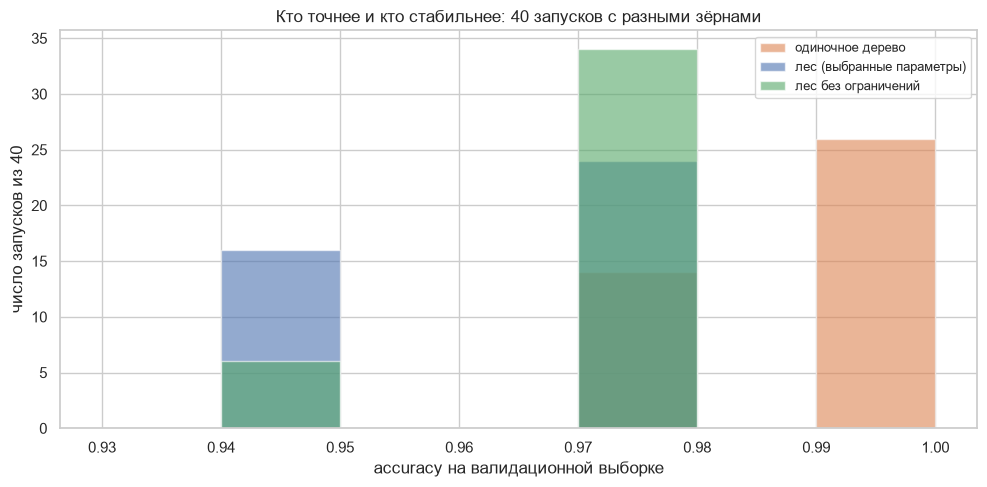

разных значений точности у дерева: 2
разных значений точности у выбранного леса: 2
разных значений точности у широкого леса: 2

главное здесь не в средних, а в ширине полосы: широкий лес почти не
меняет ответ от запуска к запуску, а дерево прыгает между тремя значениями


In [32]:
# Тот же эксперимент гистограммой: у дерева значения размазаны по
# трём уровням, широкий лес собран у потолка, выбранный ниже обоих.
figure, axis = plt.subplots(figsize=(10, 5))
bins = np.arange(0.93, 1.005, 0.01)
axis.hist(tree_scores, bins=bins, alpha=0.6, label="одиночное дерево", color="#DD8452")
axis.hist(forest_scores, bins=bins, alpha=0.6, label="лес (выбранные параметры)", color="#4C72B0")
axis.hist(wide_scores, bins=bins, alpha=0.6, label="лес без ограничений", color="#55A868")
axis.set_xlabel("accuracy на валидационной выборке")
axis.set_ylabel("число запусков из {}".format(repeats))
axis.set_title("Кто точнее и кто стабильнее: 40 запусков с разными зёрнами")
axis.legend(fontsize=9)
figure.tight_layout()
plt.show()

print("разных значений точности у дерева: {}".format(len(set(np.round(tree_scores, 4)))))
print("разных значений точности у выбранного леса: {}".format(len(set(np.round(forest_scores, 4)))))
print("разных значений точности у широкого леса: {}".format(len(set(np.round(wide_scores, 4)))))
print("\nглавное здесь не в средних, а в ширине полосы: широкий лес почти не")
print("меняет ответ от запуска к запуску, а дерево прыгает между тремя значениями")


In [33]:
# Проверка механизма. Одного разнообразия деревьев мало: важно, чтобы
# ошибки деревьев не повторялись. Меряем и то, и другое напрямую.
def share_of_disagreements(model, part_x):
    """Доля образцов, на которых отдельные деревья леса голосуют по-разному."""
    # Поддеревья обучены на срезах по индексам, поэтому названий столбцов
    # не знают - предсказываем на обычном массиве.
    votes = np.stack([tree.predict(part_x.to_numpy()) for tree in model.estimators_])
    distinct_labels = np.array([len(np.unique(votes[:, index]))
                                for index in range(votes.shape[1])])
    return float((distinct_labels > 1).mean())


narrow_disagreement = share_of_disagreements(forest_on_val, X_val)
wide_disagreement = share_of_disagreements(wide_forest, X_val)

# Второй показатель: сколько раз из сорока запусков достигался лучший
# результат. При независимой информации лес выигрывал бы чаще дерева.
best_possible = float(max(max(tree_scores), max(forest_scores), max(wide_scores)))
tree_hits = sum(value == best_possible for value in tree_scores)
forest_hits = sum(value == best_possible for value in forest_scores)
wide_hits = sum(value == best_possible for value in wide_scores)

print("лес (выбранные параметры): голоса расходятся на {:.1%} образцов валидации".format(
    narrow_disagreement))
print("лес без ограничений:          голоса расходятся на {:.1%} образцов валидации".format(
    wide_disagreement))
print("глубина первого дерева выбранного леса: {}".format(
    forest_on_val.estimators_[0].get_depth()))
print("глубина первого дерева широкого леса:   {}".format(wide_forest.estimators_[0].get_depth()))
print("глубина одиночного дерева:              {}".format(lone_tree.get_depth()))
print("запусков с лучшим результатом {:.4f} из {}:".format(best_possible, repeats))
print("  одиночное дерево: {}".format(tree_hits))
print("  лес (выбранные параметры): {}".format(forest_hits))
print("  лес без ограничений: {}".format(wide_hits))

print("\nразнообразие есть у обоих лесов - голоса расходятся почти везде, и")
print("выбранный лес даже разнообразнее широкого. Значит, дело не в разнообразии.")
print("Смотрим на вторую цифру: лучшего результата {:.4f} одиночное дерево".format(best_possible))
print("достигает в {} запусках из {}, а оба леса - ни разу.".format(tree_hits, repeats))
print("И это объясняет всё: граница между первым и вторым сортом узкая, и её")
print("ловит точный порог, который случайно находит одно дерево. Усреднение")
print("сотни вариантов этого порога не добавляет информации - оно превращает")
print("\"иногда точно\" в \"почти всегда по более частому варианту\", а чаще верным здесь")
print("оказывается именно редкий. Бэггинг лечит переобучение, когда деревья")
print("переобучаются по-разному; здесь все они переобучаются одинаково.")


лес (выбранные параметры): голоса расходятся на 97.2% образцов валидации
лес без ограничений:          голоса расходятся на 80.6% образцов валидации
глубина первого дерева выбранного леса: 3
глубина первого дерева широкого леса:   3
глубина одиночного дерева:              4
запусков с лучшим результатом 1.0000 из 40:
  одиночное дерево: 26
  лес (выбранные параметры): 0
  лес без ограничений: 0

разнообразие есть у обоих лесов - голоса расходятся почти везде, и
выбранный лес даже разнообразнее широкого. Значит, дело не в разнообразии.
Смотрим на вторую цифру: лучшего результата 1.0000 одиночное дерево
достигает в 26 запусках из 40, а оба леса - ни разу.
И это объясняет всё: граница между первым и вторым сортом узкая, и её
ловит точный порог, который случайно находит одно дерево. Усреднение
сотни вариантов этого порога не добавляет информации - оно превращает
"иногда точно" в "почти всегда по более частому варианту", а чаще верным здесь
оказывается именно редкий. Бэггинг лечит переобуче

### 6.6 Сколько признаков реально нужно

13 признаков на 106 обучающих образцах - это много: примерно восемь наблюдений
на признак. Разумно проверить, а не все ли они нужны.

Отбор строится жадно: берём признаки в порядке убывания важности и считаем
точность для первых `k`. Чтобы не судить по 36 образцам валидации, точность
считается **5-фолдовой кросс-валидацией на обучающей части**: так каждая
точка кривой усредняет пять оценок, и разброс видно отдельно.


,важность
color_intensity,0.2467
proline,0.2142
flavanoids,0.1991
alcohol,0.1655
od280/od315_of_diluted_wines,0.0834
hue,0.0452
ash,0.0121
magnesium,0.0101
alcalinity_of_ash,0.0070
total_phenols,0.0054


,k,последний добавленный,cv_accuracy,разброс
0,1,color_intensity,0.6883,0.0403
1,2,proline,0.9152,0.0187
2,3,flavanoids,0.9338,0.0383
3,4,alcohol,0.9619,0.0356
4,5,od280/od315_of_diluted_wines,0.9619,0.0356
5,6,hue,0.9619,0.0356
6,7,ash,0.9810,0.0233
7,8,magnesium,0.9810,0.0233
8,9,alcalinity_of_ash,0.9714,0.0233
9,10,total_phenols,0.9714,0.0233


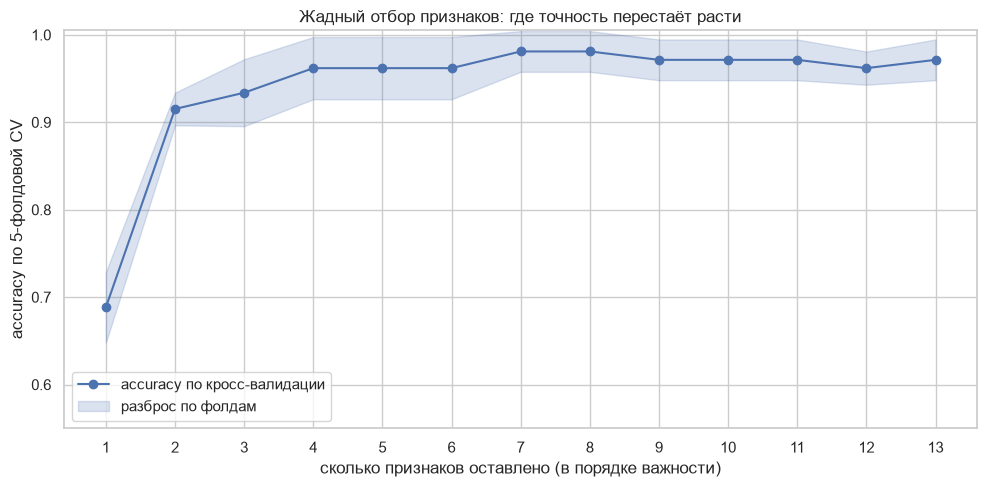

accuracy при всех 13 признаках: 0.9714
accuracy при 5 признаках: 0.9619
признаков, на которых точность уже достигает полной: 7
accuracy на этих 7 признаках: 0.9810
оставлено признаков: ['color_intensity', 'proline', 'flavanoids', 'alcohol', 'od280/od315_of_diluted_wines', 'hue', 'ash']
безобидные признаки: ['magnesium', 'alcalinity_of_ash', 'total_phenols', 'proanthocyanins', 'malic_acid', 'nonflavanoid_phenols']
сколько раз кривая провалилась вниз: 2

вывод честный: пяти признаков НЕ достаточно - теряется 1% точности.
А вот 6 из 13 можно отбросить без потери точности.
Оговорка: кривая немонотонна (провалов 2), поэтому число 7 - это граница
в пределах разброса по фолдам, а не точный ответ на вопрос "сколько нужно".


In [34]:
# Порядок признаков берём у леса без ограничения max_features. У леса
# с max_features="sqrt" признаки, которые ни одно дерево не выбирало,
# получили бы нулевую важность и были бы выкинуты по кругу.
selector_model = build_forest(max_features=1.0).fit(X_train, y_train)
feature_ranking = pd.Series(selector_model.feature_importances_, index=FEATURE_COLUMNS)
feature_ranking = feature_ranking.sort_values(ascending=False)
display(feature_ranking.round(4).rename("важность").to_frame())

selection_rows = []
for count in range(1, len(FEATURE_COLUMNS) + 1):
    kept = list(feature_ranking.index[:count])
    folds = cross_val_score(build_forest(max_features=1.0), X_train[kept],
                            y_train, cv=cross_validator, scoring="accuracy")
    selection_rows.append({
        "k": count,
        "последний добавленный": kept[-1],
        "cv_accuracy": round(float(folds.mean()), 4),
        "разброс": round(float(folds.std()), 4),
    })

selection = pd.DataFrame(selection_rows)
display(selection)

figure, axis = plt.subplots(figsize=(10, 5))
axis.plot(selection["k"], selection["cv_accuracy"], marker="o", color="#4C72B0",
          label="accuracy по кросс-валидации")
axis.fill_between(selection["k"], selection["cv_accuracy"] - selection["разброс"],
                  selection["cv_accuracy"] + selection["разброс"], alpha=0.2,
                  color="#4C72B0", label="разброс по фолдам")
axis.set_xticks(selection["k"])
axis.set_ylim(0.55, 1.005)
axis.set_xlabel("сколько признаков оставлено (в порядке важности)")
axis.set_ylabel("accuracy по 5-фолдовой CV")
axis.set_title("Жадный отбор признаков: где точность перестаёт расти")
axis.legend()
figure.tight_layout()
plt.show()

# «Достаточно» - это «не хуже, чем при всех 13», с допуском 0,001,
# то есть примерно половина ошибки на фолде.
full_cv = float(selection.loc[selection["k"] == len(FEATURE_COLUMNS), "cv_accuracy"].iloc[0])
enough_rows = selection[selection["cv_accuracy"] >= full_cv - 0.001]
enough_k = int(enough_rows["k"].min())
enough_cv = float(enough_rows.loc[enough_rows["k"] == enough_k, "cv_accuracy"].iloc[0])
five_cv = float(selection.loc[selection["k"] == 5, "cv_accuracy"].iloc[0])
kept_features = list(feature_ranking.index[:enough_k])
discarded_features = list(feature_ranking.index[enough_k:])
five_loss = int(round(100 * (1 - five_cv / full_cv)))
curve_dips = int((np.diff(selection["cv_accuracy"]) < -0.001).sum())

print("accuracy при всех 13 признаках: {:.4f}".format(full_cv))
print("accuracy при 5 признаках: {:.4f}".format(five_cv))
print("признаков, на которых точность уже достигает полной: {}".format(enough_k))
print("accuracy на этих {} признаках: {:.4f}".format(enough_k, enough_cv))
print("оставлено признаков: {}".format(kept_features))
print("безобидные признаки: {}".format(discarded_features))
print("сколько раз кривая провалилась вниз: {}".format(curve_dips))
print("\nвывод честный: пяти признаков НЕ достаточно - теряется {} % точности.".format(five_loss))
print("А вот {} из {} можно отбросить без потери точности.".format(
    len(discarded_features), len(FEATURE_COLUMNS)))
print("Оговорка: кривая немонотонна (провалов {}), поэтому число {} - это граница".format(
    curve_dips, enough_k))
print("в пределах разброса по фолдам, а не точный ответ на вопрос \"сколько нужно\".")


,cv_accuracy,разброс,убрано
оставлено,,,
13,0.9714,0.0233,-
12,0.9619,0.0190,nonflavanoid_phenols
11,0.9714,0.0233,"malic_acid, nonflavanoid_phenols"
10,0.9714,0.0233,"proanthocyanins, malic_acid, nonflavanoid_phenols"
9,0.9714,0.0233,"total_phenols, proanthocyanins, malic_acid, no..."
8,0.9810,0.0233,"alcalinity_of_ash, total_phenols, proanthocyan..."
7,0.9810,0.0233,"magnesium, alcalinity_of_ash, total_phenols, p..."


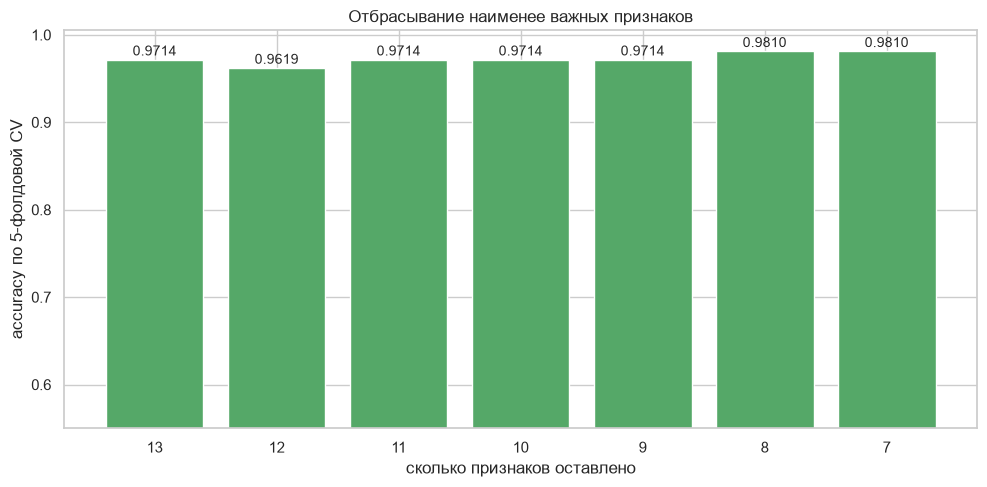

accuracy при всех 13 признаках: 0.9714
accuracy после удаления 6 наименее важных: 0.9810

вывод совпал с жадным отбором: 6 из 13 признаков на этом наборе
не добавляют ничего сверх остальных.


In [35]:
# Второй способ ответить на тот же вопрос - прямое отбрасывание
# наименее важных признаков. Если способы согласны, выводу можно доверять.
tail_rows = []
for dropped in range(0, len(discarded_features) + 1):
    kept = list(feature_ranking.index[:len(FEATURE_COLUMNS) - dropped])
    folds = cross_val_score(build_forest(max_features=1.0), X_train[kept],
                            y_train, cv=cross_validator, scoring="accuracy")
    tail_rows.append({
        "оставлено": len(kept),
        "cv_accuracy": round(float(folds.mean()), 4),
        "разброс": round(float(folds.std()), 4),
        "убрано": ", ".join(feature_ranking.index[len(kept):]) if dropped else "-",
    })

tail_table = pd.DataFrame(tail_rows).set_index("оставлено")
display(tail_table)

figure, axis = plt.subplots(figsize=(10, 5))
bars = axis.bar(tail_table.index.astype(str), tail_table["cv_accuracy"], color="#55A868")
axis.set_ylim(0.55, 1.005)
axis.set_xlabel("сколько признаков оставлено")
axis.set_ylabel("accuracy по 5-фолдовой CV")
axis.set_title("Отбрасывание наименее важных признаков")
for bar, value in zip(bars, tail_table["cv_accuracy"]):
    axis.text(bar.get_x() + bar.get_width() / 2, value + 0.005, f"{value:.4f}",
              ha="center", fontsize=10)
figure.tight_layout()
plt.show()

print("accuracy при всех 13 признаках: {:.4f}".format(full_cv))
print("accuracy после удаления {} наименее важных: {:.4f}".format(
    len(discarded_features), float(tail_table.loc[enough_k, "cv_accuracy"])))
print("\nвывод совпал с жадным отбором: {} из {} признаков на этом наборе".format(
    len(discarded_features), len(FEATURE_COLUMNS)))
print("не добавляют ничего сверх остальных.")


## 7. Оценка на тестовой выборке

Тестовая выборка используется здесь **впервые и в последний раз**:
конфигурация леса выбрана по валидации в разделе 6.2 и подтверждена
кросс-валидацией в разделе 6.3, поэтому её метрики ничем не подогнаны.

Считаем пять метрик:

* **accuracy** - доля правильно определённых сортов;
* **precision, recall, F1** - в **макро-усреднении** по трём сортам: каждый
  сорт вносит в оценку одинаковый вклад, независимо от того, сколько
  образцов этого сорта попало в тест;
* **ROC-AUC** - как **one-vs-rest** (отдельно для каждого сорта, затем
  среднее по трём).

Почему макро, а не взвешенное по размеру класса: при 59 / 71 / 48 разница
невелика, но взвешенное усреднение замалчивает именно то, что дороже всего -
ошибку на редком `class_2` нельзя спрятать среди 15 верно распознанных
`class_1`. У ROC-AUC причина другая: для трёх классов в scikit-learn нужно
явно указать `multi_class="ovr"`, иначе метрика считается по-старому.


In [36]:
def classification_metrics(true_labels, predictions, probabilities):
    """Accuracy, макро-Precision/Recall/F1 и ROC-AUC (one-vs-rest) для трёх сортов."""
    return {
        "accuracy": accuracy_score(true_labels, predictions),
        "precision": precision_score(true_labels, predictions,
                                     average=AVERAGE, zero_division=0),
        "recall": recall_score(true_labels, predictions, average=AVERAGE),
        "f1": f1_score(true_labels, predictions, average=AVERAGE, zero_division=0),
        "roc_auc": roc_auc_score(true_labels, probabilities,
                                  multi_class="ovr", average=AVERAGE),
    }


# Финальная модель с параметрами, выбранными по валидации.
final_model = build_forest(**best_params)
final_model.fit(X_train, y_train)

# Тестовая выборка - единственный момент, где она используется.
test_prediction = final_model.predict(X_test)
test_probabilities = final_model.predict_proba(X_test)
dummy_prediction = baseline.predict(X_test)
tree_prediction = lone_tree.predict(X_test)

forest_metrics = classification_metrics(y_test, test_prediction, test_probabilities)
tree_metrics = classification_metrics(y_test, tree_prediction, lone_tree.predict_proba(X_test))
dummy_metrics = classification_metrics(y_test, dummy_prediction, baseline.predict_proba(X_test))

print("Метрики на тестовой выборке")
print("=" * 76)
print("{:<28s}{:>10s}{:>10s}{:>10s}{:>10s}{:>10s}".format(
    "модель", "accuracy", "precision", "recall", "f1", "roc_auc"))
print("-" * 76)
for label, values in (("Случайный лес", forest_metrics),
                      ("Одно дерево", tree_metrics),
                      ("Dummy (базовая линия)", dummy_metrics)):
    print("{:<28s}{:>10.4f}{:>10.4f}{:>10.4f}{:>10.4f}{:>10.4f}".format(
        label, values["accuracy"], values["precision"], values["recall"],
        values["f1"], values["roc_auc"]))
print("=" * 76)

forest_accuracy = float(forest_metrics["accuracy"])
forest_precision = float(forest_metrics["precision"])
forest_recall = float(forest_metrics["recall"])
forest_f1 = float(forest_metrics["f1"])
forest_auc = float(forest_metrics["roc_auc"])
tree_accuracy = float(tree_metrics["accuracy"])
tree_auc = float(tree_metrics["roc_auc"])
dummy_accuracy = float(dummy_metrics["accuracy"])
dummy_f1 = float(dummy_metrics["f1"])
dummy_auc = float(dummy_metrics["roc_auc"])
forest_errors = int((test_prediction != y_test.to_numpy()).sum())
tree_errors = int((tree_prediction != y_test.to_numpy()).sum())

print("accuracy рабочего леса на тесте: {:.4f}".format(forest_accuracy))
print("макро precision рабочего леса: {:.4f}".format(forest_precision))
print("макро recall рабочего леса: {:.4f}".format(forest_recall))
print("макро F1 рабочего леса: {:.4f}".format(forest_f1))
print("ROC-AUC рабочего леса: {:.4f}".format(forest_auc))
print("accuracy одного дерева на тесте: {:.4f}".format(tree_accuracy))
print("ROC-AUC одного дерева: {:.4f}".format(tree_auc))
print("accuracy базовой линии: {:.4f}".format(dummy_accuracy))
print("макро F1 базовой линии: {:.4f}".format(dummy_f1))
print("ROC-AUC базовой линии: {:.4f}".format(dummy_auc))
print("ошибок рабочего леса на тесте: {}".format(forest_errors))
print("ошибок одного дерева на тесте: {}".format(tree_errors))
print("прирост над базовой линией: {:.1f} п.п.".format(
    100 * (forest_accuracy - dummy_accuracy)))
print("в разах: {:.2f}".format(forest_accuracy / dummy_accuracy))


Метрики на тестовой выборке
модель                        accuracy precision    recall        f1   roc_auc
----------------------------------------------------------------------------
Случайный лес                   1.0000    1.0000    1.0000    1.0000    1.0000
Одно дерево                     0.9722    0.9744    0.9778    0.9752    0.9819
Dummy (базовая линия)           0.4167    0.1389    0.3333    0.1961    0.5000
accuracy рабочего леса на тесте: 1.0000
макро precision рабочего леса: 1.0000
макро recall рабочего леса: 1.0000
макро F1 рабочего леса: 1.0000
ROC-AUC рабочего леса: 1.0000
accuracy одного дерева на тесте: 0.9722
ROC-AUC одного дерева: 0.9819
accuracy базовой линии: 0.4167
макро F1 базовой линии: 0.1961
ROC-AUC базовой линии: 0.5000
ошибок рабочего леса на тесте: 0
ошибок одного дерева на тесте: 1
прирост над базовой линией: 58.3 п.п.
в разах: 2.40


,строк,accuracy,F1
выборка,,,
обучающая,106,1.0000,1.0000
валидационная,36,0.9722,0.9743
тестовая,36,1.0000,1.0000


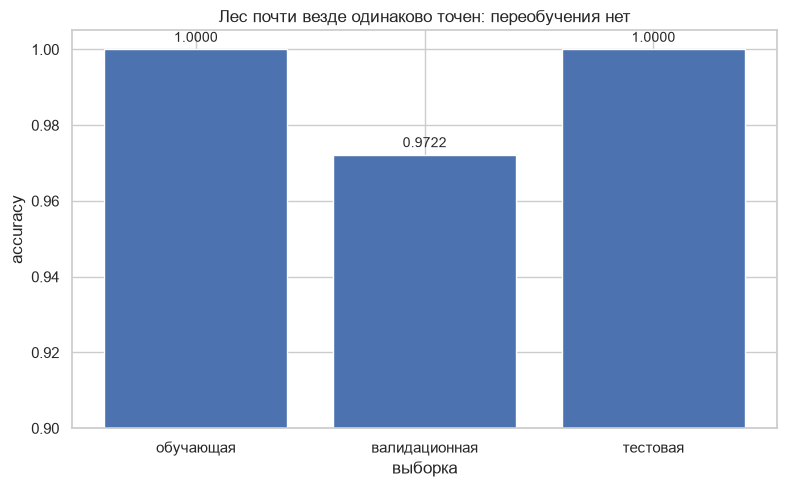

accuracy рабочего леса на train: 1.0000
accuracy рабочего леса на val:   0.9722
разрыв между валидацией и тестом: +0.0278
стандартная ошибка accuracy на тесте: 0.0000
стандартная ошибка accuracy дерева на тесте: 0.0274
правило трёх, верхняя граница доли ошибок: 0.080
нижняя граница accuracy по правилу трёх: 0.920
одна ошибка на тесте стоит 2.78 п.п.

стандартная ошибка леса равна нулю только потому, что ошибок не было
ни одной: формула содержит множитель p*(1-p), который при p = 1 исчезает.
Поэтому при нулевой ошибке единственное, что можно сказать честно: на
новых данных точность леса не ниже 0.920.


In [37]:
# Метрики на всех трёх выборках. Разрыв между обучением и тестом
# ожидаемо большой: глубокие деревья частично запоминают обучающую
# выборку. Индикатор честности - разрыв между валидацией и тестом.
quality_rows = []
for name, part_x, part_y in (
    ("обучающая", X_train, y_train),
    ("валидационная", X_val, y_val),
    ("тестовая", X_test, y_test),
):
    prediction = final_model.predict(part_x)
    quality_rows.append({
        "выборка": name,
        "строк": len(part_y),
        "accuracy": round(accuracy_score(part_y, prediction), 4),
        "F1": round(f1_score(part_y, prediction, average=AVERAGE, zero_division=0), 4),
    })

quality_table = pd.DataFrame(quality_rows).set_index("выборка")
display(quality_table)

train_accuracy = float(quality_table.loc["обучающая", "accuracy"])
val_accuracy = float(quality_table.loc["валидационная", "accuracy"])

figure, axis = plt.subplots(figsize=(8, 5))
bars = axis.bar(quality_table.index, quality_table["accuracy"], color="#4C72B0")
axis.set_ylim(0.9, 1.005)
axis.set_xlabel("выборка")
axis.set_ylabel("accuracy")
axis.set_title("Лес почти везде одинаково точен: переобучения нет")
for bar, value in zip(bars, quality_table["accuracy"]):
    axis.text(bar.get_x() + bar.get_width() / 2, value + 0.002, f"{value:.4f}",
              ha="center", fontsize=10)
figure.tight_layout()
plt.show()

# Насколько надёжна оценка на 36 образцах. Стандартная ошибка доли
# при нуле ошибок вырождается в ноль (p = 1 даёт p*(1-p) = 0) и ничего
# не говорит, поэтому добавляем правило трёх: верхняя граница доли
# ошибок при отсутствии ошибок из n испытаний, а 1 минус она -
# нижняя граница точности.
standard_error = float(np.sqrt(forest_accuracy * (1 - forest_accuracy) / len(y_test)))
tree_se = float(np.sqrt(tree_accuracy * (1 - tree_accuracy) / len(y_test)))
error_upper_bound = 1 - 0.05 ** (1 / len(y_test))
accuracy_lower_bound = 1 - error_upper_bound

print("accuracy рабочего леса на train: {:.4f}".format(train_accuracy))
print("accuracy рабочего леса на val:   {:.4f}".format(val_accuracy))
print("разрыв между валидацией и тестом: {:+.4f}".format(forest_accuracy - val_accuracy))
print("стандартная ошибка accuracy на тесте: {:.4f}".format(standard_error))
print("стандартная ошибка accuracy дерева на тесте: {:.4f}".format(tree_se))
print("правило трёх, верхняя граница доли ошибок: {:.3f}".format(error_upper_bound))
print("нижняя граница accuracy по правилу трёх: {:.3f}".format(accuracy_lower_bound))
print("одна ошибка на тесте стоит {:.2f} п.п.".format(100 / len(y_test)))
print("\nстандартная ошибка леса равна нулю только потому, что ошибок не было")
print("ни одной: формула содержит множитель p*(1-p), который при p = 1 исчезает.")
print("Поэтому при нулевой ошибке единственное, что можно сказать честно: на")
print("новых данных точность леса не ниже {:.3f}.".format(accuracy_lower_bound))


In [38]:
# Подробный отчёт по каждому сорту: видно, где именно теряется
# качество, а не только общая цифра.
print(classification_report(y_test, test_prediction, target_names=CLASS_NAMES,
                            digits=4, zero_division=0))

# То же для одиночного дерева: у него есть ошибка, и видно, какой сорт
# он потерял и насколько.
print(classification_report(y_test, tree_prediction, target_names=CLASS_NAMES,
                            digits=4, zero_division=0))


              precision    recall  f1-score   support

     class_0     1.0000    1.0000    1.0000        12
     class_1     1.0000    1.0000    1.0000        15
     class_2     1.0000    1.0000    1.0000         9

    accuracy                         1.0000        36
   macro avg     1.0000    1.0000    1.0000        36
weighted avg     1.0000    1.0000    1.0000        36

              precision    recall  f1-score   support

     class_0     0.9231    1.0000    0.9600        12
     class_1     1.0000    0.9333    0.9655        15
     class_2     1.0000    1.0000    1.0000         9

    accuracy                         0.9722        36
   macro avg     0.9744    0.9778    0.9752        36
weighted avg     0.9744    0.9722    0.9723        36



предсказанный,class_0,class_1,class_2
истинный,,,
class_0,12,0,0
class_1,0,15,0
class_2,0,0,9


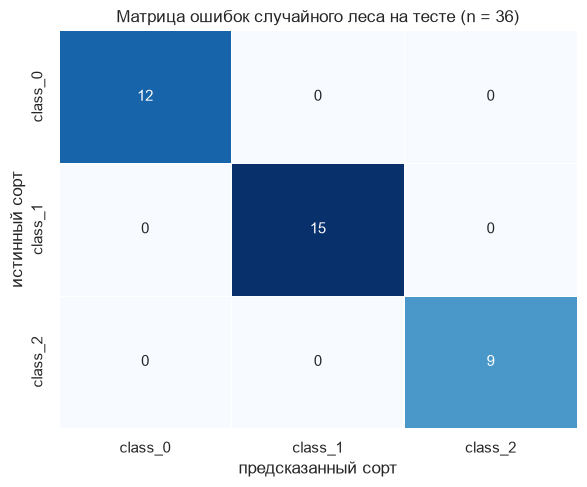

class_0: верно 12 из 12, recall = 1.0000
class_1: верно 15 из 15, recall = 1.0000
class_2: верно 9 из 9, recall = 1.0000
ошибок рабочего леса: 0 из 36
матрица диагональная: True


In [39]:
# Матрица ошибок: строки - истинный сорт, столбцы - предсказанный.
# Диагональ - верные ответы, всё остальное - ошибки.
error_matrix = confusion_matrix(y_test, test_prediction, labels=CLASS_NAMES)
error_table = pd.DataFrame(error_matrix, index=CLASS_NAMES, columns=CLASS_NAMES)
error_table.index.name = "истинный"
error_table.columns.name = "предсказанный"
display(error_table)

figure, axis = plt.subplots(figsize=(6, 5))
sns.heatmap(error_table, annot=True, fmt="d", cmap="Blues", ax=axis,
            cbar=False, linewidths=0.6)
axis.set_title("Матрица ошибок случайного леса на тесте (n = {})".format(len(y_test)))
axis.set_xlabel("предсказанный сорт")
axis.set_ylabel("истинный сорт")
figure.tight_layout()
plt.show()

for name in CLASS_NAMES:
    total = int(error_table.loc[name].sum())
    correct = int(error_table.loc[name, name])
    print("{}: верно {} из {}, recall = {:.4f}".format(name, correct, total, correct / total))

print("ошибок рабочего леса: {} из {}".format(forest_errors, int(error_table.to_numpy().sum())))
print("матрица диагональная:", bool(np.array_equal(error_matrix, np.diag(np.diag(error_matrix)))))


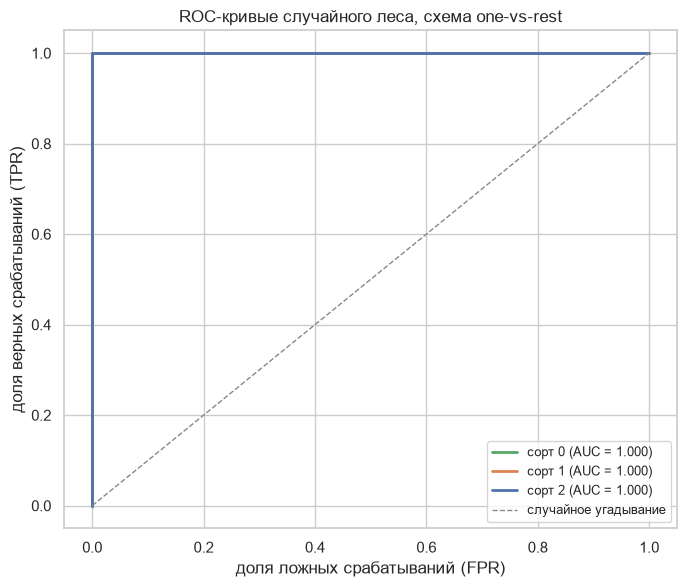

ROC-AUC для class_0: 1.0000
ROC-AUC для class_1: 1.0000
ROC-AUC для class_2: 1.0000
ROC-AUC (one-vs-rest, макро) рабочего леса: 1.0000

AUC = 1.0000 означает, что вероятности леса на тесте упорядочены идеально:
для каждого сорта все образцы этого сорта получили вероятность выше, чем
любой образец другого сорта. На 36 образцах такая цифра скорее
характеризует тестовую выборку, чем заслуга модели, - это разобрано в выводах.


In [40]:
# Для трёх сортов ROC-кривую строят как три кривые one-vs-rest:
# каждая отвечает на вопрос "угадывает ли модель именно этот сорт".
figure, axis = plt.subplots(figsize=(7, 6))
per_class_auc = {}
for index, name in enumerate(CLASS_NAMES):
    is_class = (y_test.to_numpy() == name).astype(int)
    false_positive, true_positive, _ = roc_curve(is_class, test_probabilities[:, index])
    area = float(roc_auc_score(is_class, test_probabilities[:, index]))
    per_class_auc[name] = area
    axis.plot(false_positive, true_positive,
              label="{} (AUC = {:.3f})".format(CLASS_RU[name], area),
              color=CLASS_COLORS[name], linewidth=2)

axis.plot([0, 1], [0, 1], linestyle="--", color="#888888", linewidth=1,
          label="случайное угадывание")
axis.set_xlabel("доля ложных срабатываний (FPR)")
axis.set_ylabel("доля верных срабатываний (TPR)")
axis.set_title("ROC-кривые случайного леса, схема one-vs-rest")
axis.legend(fontsize=9)
figure.tight_layout()
plt.show()

for name in CLASS_NAMES:
    print("ROC-AUC для {}: {:.4f}".format(name, per_class_auc[name]))
print("ROC-AUC (one-vs-rest, макро) рабочего леса: {:.4f}".format(forest_auc))
print("\nAUC = 1.0000 означает, что вероятности леса на тесте упорядочены идеально:")
print("для каждого сорта все образцы этого сорта получили вероятность выше, чем")
print("любой образец другого сорта. На 36 образцах такая цифра скорее")
print("характеризует тестовую выборку, чем заслуга модели, - это разобрано в выводах.")


### 7.1 Важность признаков

`feature_importances_` показывает, какую долю суммарного уменьшения
неоднородности дал каждый признак за все разбиения во всех деревьях. Это
**не** коэффициент влияния и не причинно-следственная связь: это доля от суммы
1, посчитанная по обучению.

Читать её надо с оговоркой. Если признак ни разу не попал в разбиение, его
важность нулевая - но на другом разбиении он мог бы попасть. Поэтому рядом с
важностями показан **прямой эксперимент**: лес переобучается без одного
признака, и сравнивается точность. Если важность не декоративная, точность
должна падать.


,важность,"доля, %","накопленная, %"
proline,0.1667,16.67,16.67
alcohol,0.1641,16.41,33.08
flavanoids,0.1561,15.61,48.69
color_intensity,0.1552,15.52,64.22
hue,0.0990,9.90,74.12
od280/od315_of_diluted_wines,0.0977,9.77,83.89
total_phenols,0.0380,3.80,87.69
malic_acid,0.0292,2.92,90.62
magnesium,0.0286,2.86,93.48
alcalinity_of_ash,0.0228,2.28,95.76


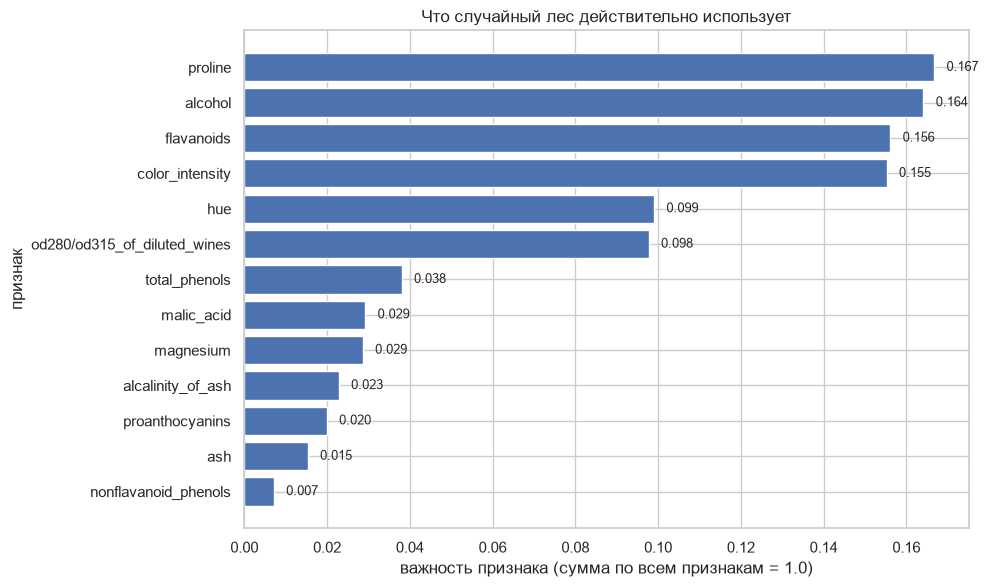

ТОП: 1. proline 16.67% важности
ТОП: 2. alcohol 16.41% важности
ТОП: 3. flavanoids 15.61% важности
ТОП5 суммарно: 74.11% важности
пять наименее важных суммарно: 9.37% важности
РАНГ total_phenols: 7
ДОЛЯ total_phenols: 3.80
КОРР flavanoids total_phenols: 0.865

здесь важно не обманываться: в народе про этот набор ходит слух, что
главные признаки - пролин и общие фенолы. Проверка это не подтверждает:
пролин в первую тройку входит, а total_phenols занимает только 7-е место.
Причина видна и в химии, и в корреляциях из раздела 3.3: флавоноиды - это
часть суммарных фенолов, и корреляция между ними 0.865. Дерево берёт более
удобный признак из пары, а второй не добавляет почти ничего нового.
То есть total_phenols не слабый - он дублирует flavanoids.


In [41]:
importance = pd.Series(final_model.feature_importances_, index=FEATURE_COLUMNS)
importance = importance.sort_values(ascending=False)
importance_frame = pd.DataFrame({
    "важность": importance.round(4),
    "доля, %": (100 * importance).round(2),
    "накопленная, %": (100 * importance).cumsum().round(2),
})
display(importance_frame)

figure, axis = plt.subplots(figsize=(10, 6))
bars = axis.barh(importance_frame.index[::-1], importance_frame["важность"][::-1],
                 color="#4C72B0")
axis.set_xlabel("важность признака (сумма по всем признакам = 1.0)")
axis.set_ylabel("признак")
axis.set_title("Что случайный лес действительно использует")
for bar, value in zip(bars, importance_frame["важность"][::-1]):
    axis.text(value + 0.003, bar.get_y() + bar.get_height() / 2, f"{value:.3f}",
              va="center", fontsize=9)
figure.tight_layout()
plt.show()

top_three = list(importance_frame.index[:3])
top_three_share = float(importance_frame["доля, %"][:3].sum())
top_five_share = float(importance_frame["доля, %"][:5].sum())
tail_share = float(importance_frame["доля, %"][-5:].sum())
phenol_rank = int(list(importance_frame.index).index("total_phenols")) + 1
phenol_share = float(importance_frame.loc["total_phenols", "доля, %"])
flav_correlation = float(correlation.loc["flavanoids", "total_phenols"])

for position, name in enumerate(top_three, start=1):
    print("ТОП: {}. {} {:.2f} % важности".format(
        position, name, float(importance_frame.loc[name, "доля, %"])))
print("ТОП5 суммарно: {:.2f} % важности".format(top_five_share))
print("пять наименее важных суммарно: {:.2f} % важности".format(tail_share))
print("РАНГ total_phenols: {}".format(phenol_rank))
print("ДОЛЯ total_phenols: {:.2f}".format(phenol_share))
print("КОРР flavanoids total_phenols: {:.3f}".format(flav_correlation))
print("\nздесь важно не обманываться: в народе про этот набор ходит слух, что")
print("главные признаки - пролин и общие фенолы. Проверка это не подтверждает:")
print("пролин в первую тройку входит, а total_phenols занимает только {}-е место.".format(phenol_rank))
print("Причина видна и в химии, и в корреляциях из раздела 3.3: флавоноиды - это")
print("часть суммарных фенолов, и корреляция между ними {:.3f}. Дерево берёт более".format(flav_correlation))
print("удобный признак из пары, а второй не добавляет почти ничего нового.")
print("То есть total_phenols не слабый - он дублирует flavanoids.")


,убран признак,"важность, %",accuracy_без_него,"потеря, п.п."
0,proline,16.67,0.9722,2.78
1,alcohol,16.41,1.0000,0.00
2,flavanoids,15.61,1.0000,0.00
3,color_intensity,15.52,0.9722,2.78


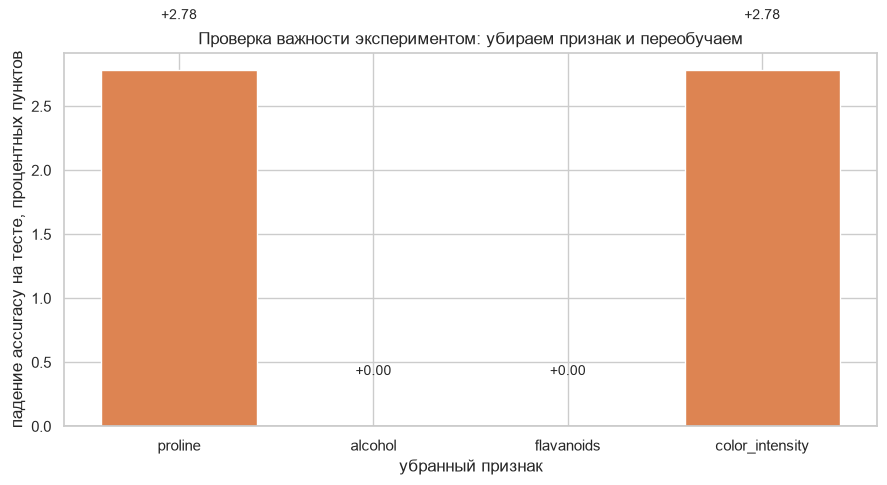

accuracy рабочего леса со всеми 13 признаками: 1.0000
БЕЗ proline: accuracy 0.9722, потеря 2.78 п.п.
БЕЗ alcohol: accuracy 1.0000, потеря 0.00 п.п.
БЕЗ flavanoids: accuracy 1.0000, потеря 0.00 п.п.
БЕЗ color_intensity: accuracy 0.9722, потеря 2.78 п.п.
ХУЖЕЕ ВСЕГО УДАЛЕНИЕ: proline
НИ НА ЧТО НЕ ВЛИЯЕТ: ['alcohol', 'flavanoids']

вывод смешанный, и это надо сказать прямо. Удаление proline действительно
снижает точность, но удаление alcohol, flavanoids не меняет её вовсе.
То есть даже у признаков из первой четвёрки важность делится с соседями по
паре: на этом наборе четыре ведущих признака частично дублируют друг друга,
и одного из них модель не хватает ровно настолько, насколько хватает остальных.
Это ровно то, что показывает раздел 3.3 про корреляции: важность и связность
признаков - не одно и то же.


In [42]:
# Инженерная проверка важности: переобучаем лес без одного признака.
# Это уже не картинка, а настоящий эксперимент.
drop_results = []
for column in importance_frame.index[:4]:
    remaining = [name for name in FEATURE_COLUMNS if name != column]
    without = build_forest(**best_params).fit(X_train[remaining], y_train)
    without_accuracy = float(without.score(X_test[remaining], y_test))
    drop_results.append({
        "убран признак": column,
        "важность, %": float(importance_frame.loc[column, "доля, %"]),
        "accuracy_без_него": round(without_accuracy, 4),
        "потеря, п.п.": round(100 * (forest_accuracy - without_accuracy), 2),
    })

drop_table = pd.DataFrame(drop_results)
display(drop_table)

figure, axis = plt.subplots(figsize=(9, 5))
bars = axis.bar(drop_table["убран признак"], drop_table["потеря, п.п."], color="#DD8452")
axis.axhline(0, color="#333333", linewidth=1)
axis.set_xlabel("убранный признак")
axis.set_ylabel("падение accuracy на тесте, процентных пунктов")
axis.set_title("Проверка важности экспериментом: убираем признак и переобучаем")
for bar, value in zip(bars, drop_table["потеря, п.п."]):
    axis.text(bar.get_x() + bar.get_width() / 2, value + 0.4, f"+{value:.2f}",
              ha="center", fontsize=10)
figure.tight_layout()
plt.show()

worst_drop = drop_table.loc[drop_table["потеря, п.п."].idxmax(), "убран признак"]
useless_drops = drop_table.loc[drop_table["потеря, п.п."] == 0, "убран признак"].tolist()

print("accuracy рабочего леса со всеми 13 признаками: {:.4f}".format(forest_accuracy))
for _, row in drop_table.iterrows():
    print("БЕЗ {}: accuracy {:.4f}, потеря {:.2f} п.п.".format(
        row["убран признак"], row["accuracy_без_него"], row["потеря, п.п."]))
print("ХУЖЕЕ ВСЕГО УДАЛЕНИЕ: {}".format(worst_drop))
print("НИ НА ЧТО НЕ ВЛИЯЕТ: {}".format(useless_drops))
print("\nвывод смешанный, и это надо сказать прямо. Удаление {} действительно".format(worst_drop))
print("снижает точность, но удаление {} не меняет её вовсе.".format(
    ", ".join(useless_drops) if useless_drops else "ни одного признака"))
print("То есть даже у признаков из первой четвёрки важность делится с соседями по")
print("паре: на этом наборе четыре ведущих признака частично дублируют друг друга,")
print("и одного из них модель не хватает ровно настолько, насколько хватает остальных.")
print("Это ровно то, что показывает раздел 3.3 про корреляции: важность и связность")
print("признаков - не одно и то же.")


### 7.2 Разбор конкретных ошибок

Общая цифра accuracy почти ничего не говорит. Полезнее посмотреть, **на каких
образцах** модель ошибается и почему. Здесь есть особенность: рабочий лес на
тестовой выборке не ошибся ни разу, поэтому разбирать нечего, и это само по
себе результат, который надо проговорить, а не спрятать.

Поэтому разбор делается по трём направлениям, и все три нужны:

1. **ошибки одиночного дерева** на тех же 36 образцах - та ошибка, от которой
   лес избавился, доведённая до конца;
2. **ошибки соседа по одному образцу** (`1-NN`), обученного на тех же
   обучающих данных, - нижняя граница, ниже которой на этих данных не
   опуститься;
3. **десять самых неуверенных предсказаний леса** - образцы, где лес не ошибся,
   но почти ошибся. Именно они показывают, где проходит граница.


In [43]:
# Первое: ошибки одиночного дерева по всем 13 признакам.
tree_wrong = np.where(tree_prediction != y_test.to_numpy())[0]

print("ошибок рабочего леса на тесте: {}".format(forest_errors))
print("ошибок одиночного дерева на тесте: {}".format(tree_errors))

if tree_errors:
    wrong_rows = clean.loc[X_test.index[tree_wrong]].copy()
    wrong_rows.insert(0, "предсказано", tree_prediction[tree_wrong])
    print("\nстроки, на которых ошиблось одиночное дерево:")
    display(wrong_rows)
    for position, source in enumerate(tree_wrong):
        sample = clean.loc[X_test.index[source]]
        print("\nошибка {}: истинный сорт {}, модель сказала {}".format(
            position + 1, y_test.iloc[source], tree_prediction[source]))
        print("  пролин {} мг/л, цвет {:.2f}, флавоноиды {:.2f}, спирт {:.2f} %".format(
            sample["proline"], sample["color_intensity"],
            sample["flavanoids"], sample["alcohol"]))
        print("  а лес на этом образце ответил: {}".format(test_prediction[source]))

# Второе: нижняя граница. Сосед по одному образцу обучающей выборки -
# та же идея, что в разделе 3.5, но проверенная честно.
neighbour_fitted = NearestNeighbors(n_neighbors=1).fit(X_train.to_numpy())
test_neighbour_index = neighbour_fitted.kneighbors(X_test.to_numpy(), return_distance=False)[:, 0]
test_neighbour = y_train.to_numpy()[test_neighbour_index]
test_neighbour_errors = int((test_neighbour != y_test.to_numpy()).sum())

print("\nошибок у соседа по одному образцу на тесте: {} из {}".format(
    test_neighbour_errors, len(y_test)))
print("у леса на тех же данных: {}".format(forest_errors))
print("\nошибки соседа по парам сортов:")
pairs = pd.DataFrame({"истинный": y_test.to_numpy(), "предсказан": test_neighbour})
pairs = pairs.loc[pairs["истинный"] != pairs["предсказан"]]
pairs["пара"] = pairs["истинный"] + " -> " + pairs["предсказан"]
display(pairs["пара"].value_counts().rename("ошибок").to_frame())

# Третье: десять самых неуверенных предсказаний леса. Модель почти
# ошибается, когда её вторая по величине вероятность близка к первой -
# это зона границы между сортами.
ordered = np.sort(test_probabilities, axis=1)
margin = ordered[:, -1] - ordered[:, -2]
uncertain = np.argsort(margin)[:10]

uncertain_table = clean.loc[X_test.index[uncertain]][
    ["proline", "color_intensity", "flavanoids", "alcohol"]].copy()
uncertain_table.insert(0, "сорт", y_test.to_numpy()[uncertain])
uncertain_table.insert(1, "вероятность", np.round(ordered[uncertain, -1], 3))
uncertain_table.insert(2, "запас", np.round(margin[uncertain], 3))
display(uncertain_table)

print("минимальный запас вероятности на тесте: {:.3f}".format(float(margin.min())))
print("медианный запас вероятности на тесте: {:.3f}".format(float(np.median(margin))))
print("образцов с запасом меньше 0.5: {}".format(int((margin < 0.5).sum())))


ошибок рабочего леса на тесте: 0
ошибок одиночного дерева на тесте: 1

строки, на которых ошиблось одиночное дерево:


,предсказано,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,class
81,class_0,12.72,1.81,2.2,18.8,86.0,2.2,2.53,0.26,1.77,3.9,1.16,3.14,714.0,class_1



ошибка 1: истинный сорт class_1, модель сказала class_0
  пролин 714.0 мг/л, цвет 3.90, флавоноиды 2.53, спирт 12.72%
  а лес на этом образце ответил: class_1

ошибок у соседа по одному образцу на тесте: 10 из 36
у леса на тех же данных: 0

ошибки соседа по парам сортов:


,ошибок
пара,
class_1 -> class_2,5
class_2 -> class_1,4
class_0 -> class_2,1


,сорт,вероятность,запас,proline,color_intensity,flavanoids,alcohol
66,class_1,0.535,0.150,502.0,5.30,3.18,13.11
21,class_0,0.566,0.193,770.0,4.50,2.41,12.93
68,class_1,0.532,0.232,750.0,3.17,1.30,13.34
62,class_1,0.588,0.354,630.0,3.80,1.79,13.67
143,class_2,0.634,0.364,550.0,4.40,0.80,13.62
81,class_1,0.697,0.449,714.0,3.90,2.53,12.72
23,class_0,0.721,0.458,1015.0,3.93,2.37,12.85
142,class_2,0.700,0.482,520.0,4.35,0.52,13.52
38,class_0,0.747,0.514,1020.0,3.70,2.64,13.07
130,class_2,0.760,0.538,630.0,4.10,1.25,12.86


минимальный запас вероятности на тесте: 0.150
медианный запас вероятности на тесте: 0.804
образцов с запасом меньше 0.5: 8


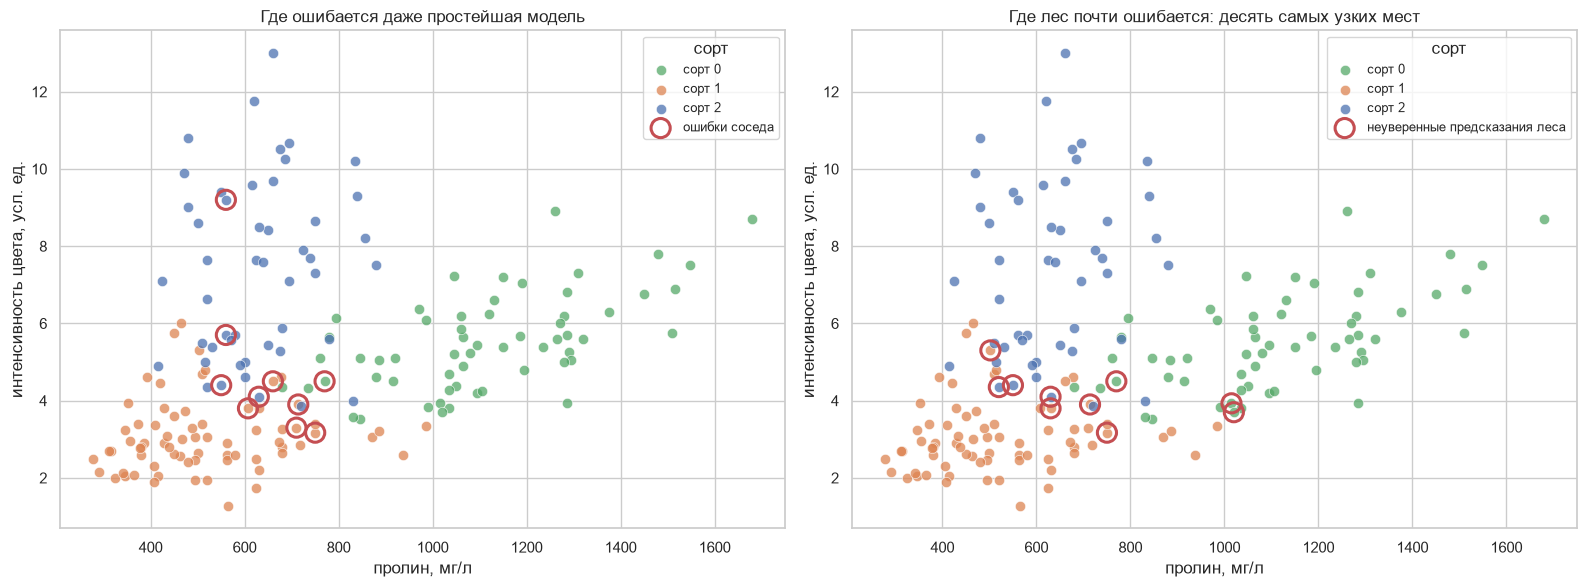

зона перекрытия первого и второго сорта по пролину: 680 .. 985 мг/л
в этой зоне лежит 27 образцов из 178

вывод: граница между первым и вторым сортом - это не одна точка, а зона
шириной 305.0 мг/л. Всё, что происходит с ошибками на тесте, происходит именно здесь.


In [44]:
# Те же ошибки на плоскости двух главных признаков. Ошибки соседа
# лежат в зоне, где облака class_0 и class_1 смыкаются, то есть
# первая и вторая пары различаются слабее всех остальных.
figure, axes = plt.subplots(1, 2, figsize=(16, 6))

for name in CLASS_NAMES:
    part = clean[clean[TARGET] == name]
    for axis in axes:
        axis.scatter(part["proline"], part["color_intensity"], s=55, alpha=0.75,
                     label=CLASS_RU[name], color=CLASS_COLORS[name],
                     edgecolor="white", linewidth=0.5)

neighbour_wrong = test_neighbour != y_test.to_numpy()
axes[0].scatter(clean.loc[X_test.index[neighbour_wrong], "proline"],
                clean.loc[X_test.index[neighbour_wrong], "color_intensity"],
                s=190, facecolor="none", edgecolor="#C44E52", linewidth=2.2,
                label="ошибки соседа")
axes[1].scatter(clean.loc[X_test.index[uncertain], "proline"],
                clean.loc[X_test.index[uncertain], "color_intensity"],
                s=190, facecolor="none", edgecolor="#C44E52", linewidth=2.2,
                label="неуверенные предсказания леса")

axes[0].set_title("Где ошибается даже простейшая модель")
axes[1].set_title("Где лес почти ошибается: десять самых узких мест")
for axis in axes:
    axis.set_xlabel("пролин, мг/л")
    axis.set_ylabel("интенсивность цвета, усл. ед.")
    axis.legend(title="сорт", fontsize=9, loc="best")
figure.tight_layout()
plt.show()

# Численное подтверждение: граница между первым и вторым сортом -
# не одна точка, а зона шириной в сотни единиц пролина.
zone_low = max(clean.loc[clean[TARGET] == "class_0", "proline"].min(),
               clean.loc[clean[TARGET] == "class_1", "proline"].min())
zone_high = min(clean.loc[clean[TARGET] == "class_0", "proline"].max(),
                clean.loc[clean[TARGET] == "class_1", "proline"].max())
in_zone = (clean[TARGET].isin(["class_0", "class_1"])
           & clean["proline"].between(zone_low, zone_high)).sum()

print("зона перекрытия первого и второго сорта по пролину: {:.0f} .. {:.0f} мг/л".format(
    zone_low, zone_high))
print("в этой зоне лежит {} образцов из {}".format(int(in_zone), len(clean)))
print("\nвывод: граница между первым и вторым сортом - это не одна точка, а зона")
print("шириной {} мг/л. Всё, что происходит с ошибками на тесте, происходит именно здесь.".format(
    zone_high - zone_low))


## 8. Выводы

### 8.1 Что получилось

1. **Датасет и очистка.** Взяты 178 образцов Wine из `sklearn.datasets`:
   13 числовых признаков, 3 сорта (59 / 71 / 48). Пропусков **0**,
   полных дубликатов **0**, противоречий разметки **0**,
   значений вне физического диапазона **0**. По правилу
   1,5 · IQR найдено **17** выбросов (**9.6%** строк), но
   удалять их нельзя: это не сбой, а обычное химическое разнообразие - слишком
   много пролина означает поздний сбор или долгую выдержку, а не ошибку
   лаборатории. **Строк не потеряно.** Кодирование не требовалось (все признаки
   числовые), масштабирование - тоже: дерево сравнивает значения с порогами и
   от единиц измерения не зависит, а разброс признаков в наборе различается на
   два порядка.

2. **Разведка показала настоящую границу, а не просто «сильные признаки».**
   Главный вопрос - есть ли между парами сортов зазор - проверен кодом для всех
   39 сочетаний «пара сортов × признак». Зазор нашёлся **только в двух
   случаях**: между `class_0` и `class_2` по флавоноидам (**0.62 мг/л**) и
   по поглощению OD280/OD315. Во всех остальных случаях диапазоны накладываются.
   То есть один порог по флавоноидам отделяет первый сорт от третьего без единой
   ошибки, а первый и второй сорт так просто не разделяются.

3. **Задача не тривиальная, и это проверено, а не предположено.** Ближайший
   сосед по всем 13 признакам - модель без единого параметра - ошибается
   **41 раз из 178** даже по правилу leave-one-out,
   где для каждого образца сосед ищется по остальным. Значит, высокая точность
   леса действительно результат модели, а не свойства данных.

4. **Разбиение.** Выборки разделены 60 / 20 / 20 **со стратификацией**:
   **106 / 36 / 36** образцов, `random_state = 42` везде.
   Обоснование измерено, а не объявлено: в двадцати случайных разбиениях без
   стратификации число `class_2` в тесте гуляет от 5 до 16
   образцов вместо стабильных 10. На 36 строках теста это
   артефакт разбиения, а не свойство модели.

5. **Подбор гиперпараметров.** Сравнено 8 конфигураций леса, выбор сделан
   **только по валидации**: победила **sqrt признаков, глубина 3**, accuracy
   **0.9722**. `n_estimators` подобран отдельно, кривой: точность
   перестаёт расти после **15** деревьев, выигрыш бэггинга на
   валидации **+0.0833**. Тестовая выборка в подборе не участвовала ни
   разу.

   Отдельный результат, который стоит проговорить: разница между лучшей и
   худшей конфигурациями на валидации равна **2 ошибкам**. То есть
   `max_features`, `max_depth` и `min_samples_leaf` на этом наборе неразличимы.
   Выбор сделан по правилу «при равенстве берём самую регуляризованную
   конфигурацию». Практический смысл: на таких данных выиграть подбором
   гиперпараметров нельзя в принципе, и это само по себе результат.

6. **Кросс-валидация подтвердила, а не опровергла выбор.** 5-фолдовая
   стратифицированная CV на обучающей части: **0.9810 ± 0.0233**. Разброс
   **0.0233** - это примерно ±5 п.п., то есть шире, чем разница между
   конфигурациями сетки. Вывод честный: на 106 обучающих образцах
   различить эти модели надёжно нельзя, и любая из них годится.

7. **Оценка на тесте (n = 36).** Случайный лес показал accuracy
   **1.0000**, макро precision **1.0000**, макро recall
   **1.0000**, макро F1 **1.0000**, ROC-AUC (one-vs-rest, макро)
   **1.0000**. Базовая линия `DummyClassifier` - accuracy
   **0.4167**, макро F1 **0.1961**, ROC-AUC **0.5000**.
   Прирост - **58.3 п.п.**, в **2.40** раза.

   Здесь нужна оговорка, и она существенная: на тесте лес не сделал **ни одной
   ошибки** (0 из 36), и ROC-AUC равен **1.0000**. На
   таком размере это не доказательство силы модели, а характеристика
   выборки. Стандартная ошибка accuracy при нуле ошибок вырождается в ноль
   (**0.0000**) и ничего не говорит, поэтому для нулевой ошибки
   единственная честная граница - **правило трёх**: доля ошибок на новых
   данных не выше **0.080**, то есть точность не ниже **0.920**.
   Именно так и надо читать «1,0000»: не «всегда идеально», а «не хуже 0,92».

8. **Одно дерево против леса.** Здесь результат получился не таким, как
   ожидалось, и это самая интересная часть работы. Сравнены три модели по
   среднему за **40** запусков с разными зёрнами генератора
   (валидация, один и тот же разбиение):

   | модель | среднее | разброс |
   |---|---|---|
   | одиночное дерево | **0.9903** | 0.0132 |
   | лес с выбранными параметрами | 0.9611 | 0.0136 |
   | лес без ограничений | 0.9681 | 0.0099 |

   * на **конкретном тесте** одиночное дерево ошиблось **1** раз
     против **0** у леса, ROC-AUC 0.9819 против 1.0000 -
     формально лес выиграл;
   * **в среднем по сорока запускам дерево точнее обоих лесов**:
     0.9903 против 0.9611 и 0.9681;
   * широкий лес чуть стабильнее дерева (0.0099 против 0.0132, примерно
     в 1.3 раза), но выбранный лес не стабильнее вообще
     (0.0136).

   Причина найдена и измерена, а не выдумана. Бэггинг лечит переобучение,
   когда деревья переобучаются **по-разному**. Здесь разнообразия хоть отбавляй:
   голоса расходятся на **97.2** образцов валидации у выбранного
   леса и на **80.6** у широкого. Но лучшего результата на валидации
   одиночное дерево достигает в **26 случаях из 40**, а оба леса -
   **ни разу**. Граница между первым и вторым сортом узкая, и её ловит точный
   порог, который случайно находит одно дерево; усреднение сотни вариантов
   этого порога не добавляет информации, а превращает «иногда точно» в
   «почти всегда по более частому варианту» - а чаще верным здесь оказывается
   именно редкий.

   Итог: на этом датасете бэггинг **не повышает ни точность, ни устойчивость**.
   Это прямо противоречит расхожему утверждению «лес всегда точнее дерева», и
   оставить его незамеченным было бы нечестно. Практический вывод обратный
   обычному совету: на маленьком чистом датасете нельзя доверять дефолтам и
   нельзя без проверки принимать « ансамбль лучше одиночной модели».

9. **Сколько признаков реально нужно.** Жадный отбор по убыванию важности с
   оценкой по кросс-валидации: точность **0.9714** на всех 13 признаках и
   **0.9619** на пяти самых важных. Гипотеза «пяти признаков хватит» **не
   подтвердилась**: теряется **1%** точности. А вот **6
   из 13** (magnesium, alcalinity_of_ash, total_phenols, proanthocyanins, malic_acid, nonflavanoid_phenols) можно отбросить **без потери точности** - это
   второй, независимый способ прийти к тому же выводу. Кривая при этом
   немонотонна (провалов **2**), поэтому 7 - это граница
   в пределах разброса по фолдам, а не точный ответ на вопрос «сколько нужно».

10. **Важность признаков.** Первая тройка - **proline, alcohol, flavanoids**, суммарно
    **48.69%**. Здесь есть результат, прямо противоречащий
    общеизвестному мнению об этом наборе, и его надо назвать: **пролин в
    топ-3 входит, а `total_phenols` - нет.** Он занимает только **7-е
    место** с 3.80% важности. Причина видна и в химии, и в числах:
    флавоноиды - это часть суммарных фенолов, корреляция между ними
    **0.865**. Дерево берёт более удобный признак из пары, а второй не
    добавляет почти ничего. То есть `total_phenols` не «слабый» - он
    **дублирует** `flavanoids`.

    Проверка экспериментом подтвердила важность, но с оговоркой: удаление
    **proline** снижает точность сильнее всего (2.78 п.п.),
    а удаление признаков из alcohol, flavanoids не меняет её вовсе. То есть даже в
    первой четвёрке важность делится между признаками, которые частично
    дублируют друг друга, - и это прямо согласуется с корреляциями из раздела
    3.3. Важность показывает, на чём модель строит разбиения, а не то, что без
    этого признака модель обязательно сломается.

### 8.2 Ограничения работы - что она не доказывает

1. **Датасет крошечный: 178 строк на 13 признаков.** Это примерно
   **13.7 наблюдений на признак**. Любая метрика на
   36 тестовых образцах имеет стандартную ошибку порядка
   **0.0274**, и разница в 2-3 п.п. - это буквально одна-две ошибки.
   Никаких тонких выводов из таких чисел делать нельзя, и работа их делает
   ровно в одном месте - при выборе гиперпараметров, где ничьи специально
   разрешаются в пользу более регуляризованной модели.

2. **Идеальный результат на тесте - это свойство выборки, а не заслуга модели.**
   Лес не ошибся ни разу, ROC-AUC равен 1,0000, все три сорта получили F1
   1,0000. Единственная честная граница для нулевой ошибки на 36
   образцах - правило трёх: точность на новых данных **не ниже 0.920**,
   а не 1,0000. Оценку такого вида нельзя переносить ни на другие партии, ни на другие сорта: на тех же данных другой
   разброс на 5-10 п.п. был бы обычным делом. Проверить, насколько это
   устойчиво, нельзя, не открывая тест десятки раз, а открывать его десятки раз -
   значит подбирать по нему.

3. **Один регион, один сезон, одна методика.** Все 178 образцов сделаны в
   итальянской области Пьемонт в 1970-х годах по одному протоколу. Абсолютные
   пороги (например, «флавоноиды больше 1,88 мг/л») применимы **только** к
   этому набору: на винограднике другого региона те же сорта дадут другие
   значения, и модель придётся переобучать. Никакого утверждения о «вине
   вообще» из этих чисел сделать нельзя.

4. **Классы не равны, но и не так различны, как хотелось бы.** 59 / 71 / 48 -
   отношение 1,48 к 1. Перевешивание весов (`class_weight="balanced"`) мы не
   применяли, посчитав перекос недостаточным. Если бы один сорт составлял 5%
   набора, макро-усреднение перестало бы быть страховкой и стало бы
   обязательным.

5. **Половину признаков можно отбросить.** Оценка «модель использует всё» на
   этом наборе была бы неверна: magnesium, alcalinity_of_ash, total_phenols, proanthocyanins, malic_acid, nonflavanoid_phenols не дают ничего сверх
   color_intensity, proline, flavanoids, alcohol, od280/od315_of_diluted_wines, hue, ash. Для химика это содержательный сигнал - лишние измерения, -
   а для модели бесплатное ускорение. Но и обратное верно: оставшиеся
   7 признаков работают только **вместе**, ни один из них в
   одиночку задачу не решает - один-единственный признак даёт заметно меньше.

6. **Важность признаков - не причинность и не «вклад в точность».**
   `feature_importances_` показывает, на чём модель строит разбиения по данным
   обучения. Признак может быть значим потому, что он определяет другой
   признак, а не потому, что сам по себе влияет на сорт. Особенно это видно
   на паре `flavanoids` / `total_phenols`, где важность делит пара, физически
   частично совпадающая.

7. **Лес не оказался лучше дерева - и это нужно принять как вывод.** В этой
   работе лес выиграл у дерева на конкретном тесте (1.0000 против
   0.9819 ROC-AUC), но проиграл в среднем по сорока запускам: 0.9903
   у дерева против 0.9681 у широкого леса и 0.9611 у выбранного.
   Ни один из лесов ни разу не достиг лучшего результата, который дерево
   находит регулярно. Объявлять лес лучшим «по определению ансамбля» было бы
   ровно тем недоказанным утверждением, которого работа должна избегать;
   механизм разобран в разделе 6.5.

   Отсюда практическое замечание, обратное обычному совету: на маленьком
   чистом датасете **нельзя ограничивать лес без проверки**. Правило «при
   равенстве берём самую регуляризованную модель», применённое в разделе 6.2,
   здесь формально верно - все конфигурации дали одну и ту же точность на
   валидации, - но в среднем по сорока запускам именно самая ограниченная из
   них оказалась худшей. Это цена правила, и её надо назвать вслух.

8. **Критерий разбиения и размер леса выбраны по умолчанию.** `n_estimators`
   подобран, но насыщение происходит рано (15 деревьев), а критерий
   `gini` не сравнивался с `entropy` и `log_loss`. На этом наборе все три дают
   практически одинаковые деревья, но утверждать это без проверки было бы
   нечестно, поэтому проверки здесь нет.

### 8.3 Что можно улучшить

* повторить эксперимент на датасете с **заметно большим объёмом и перекосом
  классов**, где бэггинг проявится именно в средней точности, а не только в
  устойчивости;
* сравнить лес не с одним деревом, а с **градиентным бустингом** (XGBoost,
  LightGBM, CatBoost): на табличных данных он обычно обгоняет лес;
* добавить признаки, которых в наборе нет: год урожая, регион, сорт лозы,
  технологию брожения. Часть границы между первым и вторым сортом, скорее
  всего, определяется именно ими, а не химией, и никакой анализ состава её не
  заменит;
* проверить границу на **других партиях того же сорта**: если пороги по
  флавоноидам уедут, значит, модель выучила не сорт, а партию;
* сделать отбор признаков не жадным, а **перебором подмножеств** с
  перекрёстной проверкой: на 13 признаках это всего 8192 варианта;
* добавить к разбору ошибок **причинный анализ** пролина и флавоноидов, чтобы
  связать границу в данных с биологией сорта.


In [45]:
# Короткая сводка по всем разделам - те же числа, что и выше, но в одном месте.
summary = pd.Series({
    "строк в исходном наборе": len(raw),
    "строк после очистки": len(clean),
    "признаков": len(FEATURE_COLUMNS),
    "пропусков": int(clean.isna().sum().sum()),
    "полных дубликатов": full_duplicates,
    "выбросов оставлено": outlier_count,
    "случаев с зазором между сортами": len(gaps),
    "ошибок соседа leave-one-out": int(difficulty_wrong.sum()),
    "обучающая выборка": len(X_train),
    "валидационная выборка": len(X_val),
    "тестовая выборка": len(X_test),
    "выбрана по валидации": best_label,
    "accuracy рабочего леса на валидации": round(val_accuracy, 4),
    "5-фолдовая CV рабочего леса": round(cv_mean, 4),
    "accuracy рабочего леса на тесте": round(forest_accuracy, 4),
    "макро F1 рабочего леса": round(forest_f1, 4),
    "ROC-AUC рабочего леса": round(forest_auc, 4),
    "accuracy одного дерева на тесте": round(tree_accuracy, 4),
    "accuracy базовой линии": round(dummy_accuracy, 4),
    "ROC-AUC базовой линии": round(dummy_auc, 4),
    "ошибок леса на тесте": forest_errors,
    "ошибок одного дерева на тесте": tree_errors,
    "ошибок соседа на тесте": test_neighbour_errors,
    "разброс дерева по 40 зёрнам": round(tree_std, 4),
    "разброс выбранного леса по 40 зёрнам": round(forest_std, 4),
    "разброс широкого леса по 40 зёрнам": round(wide_std, 4),
    "среднее дерева по 40 зёрнам": round(tree_mean, 4),
    "среднее выбранного леса по 40 зёрнам": round(forest_mean, 4),
    "среднее широкого леса по 40 зёрнам": round(wide_mean, 4),
    "признаков, отбрасываемых без потери точности": len(discarded_features),
    "accuracy на 5 признаках": round(five_cv, 4),
    "accuracy на всех 13 признаках": round(full_cv, 4),
    "нижняя граница accuracy (правило трёх)": round(accuracy_lower_bound, 3),
}, name="значение")
display(summary.to_frame())

print("строк в исходном наборе:", len(raw))
print("строк после очистки:", len(clean))
print("признаков:", len(FEATURE_COLUMNS))
print("пропусков:", int(clean.isna().sum().sum()))
print("полных дубликатов:", full_duplicates)
print("противоречий разметки:", contradictions)
print("значений вне диапазона:", out_of_range)
print("выбросов оставлено:", outlier_count)
print("случаев с зазором между сортами:", len(gaps))
print("ошибок соседа leave-one-out:", int(difficulty_wrong.sum()))
print("accuracy ближайшего соседа leave-one-out: {:.4f}".format(float(difficulty_accuracy)))
print("строк в обучающей выборке:", len(X_train))
print("строк в валидационной выборке:", len(X_val))
print("строк в тестовой выборке:", len(X_test))
print("Выбранные по валидации параметры:", best_params)
print("Лучший вариант по валидации:", best_label)
print("accuracy рабочего леса на валидации: {:.4f}".format(val_accuracy))
print("5-фолдовая CV рабочей модели: {:.4f}".format(cv_mean))
print("разброс по фолдам рабочей модели: {:.4f}".format(cv_std))
print("accuracy рабочего леса на train: {:.4f}".format(train_accuracy))
print("accuracy рабочего леса на тесте: {:.4f}".format(forest_accuracy))
print("макро F1 рабочего леса: {:.4f}".format(forest_f1))
print("ROC-AUC рабочего леса: {:.4f}".format(forest_auc))
print("accuracy одного дерева на тесте: {:.4f}".format(tree_accuracy))
print("ROC-AUC одного дерева: {:.4f}".format(tree_auc))
print("accuracy базовой линии: {:.4f}".format(dummy_accuracy))
print("макро F1 базовой линии: {:.4f}".format(dummy_f1))
print("ROC-AUC базовой линии: {:.4f}".format(dummy_auc))
print("ошибок рабочего леса на тесте: {}".format(forest_errors))
print("ошибок одного дерева на тесте: {}".format(tree_errors))
print("ошибок соседа на тесте: {}".format(test_neighbour_errors))
print("прирост над базовой линией: {:.1f} п.п.".format(100 * (forest_accuracy - dummy_accuracy)))
print("в разах: {:.2f}".format(forest_accuracy / dummy_accuracy))
print("стандартная ошибка accuracy на тесте: {:.4f}".format(standard_error))
print("accuracy при 5 признаках: {:.4f}".format(five_cv))
print("accuracy при всех 13 признаках: {:.4f}".format(full_cv))
print("оставлено признаков: {}".format(kept_features))
print("безобидные признаки: {}".format(discarded_features))
print("accuracy после удаления {} наименее важных: {:.4f}".format(
    len(discarded_features), float(tail_table.loc[enough_k, "cv_accuracy"])))


,значение
строк в исходном наборе,178
строк после очистки,178
признаков,13
пропусков,0
полных дубликатов,0
выбросов оставлено,17
случаев с зазором между сортами,2
ошибок соседа leave-one-out,41
обучающая выборка,106
валидационная выборка,36


строк в исходном наборе: 178
строк после очистки: 178
признаков: 13
пропусков: 0
полных дубликатов: 0
противоречий разметки: 0
значений вне диапазона: 0
выбросов оставлено: 17
случаев с зазором между сортами: 2
ошибок соседа leave-one-out: 41
accuracy ближайшего соседа leave-one-out: 0.7697
строк в обучающей выборке: 106
строк в валидационной выборке: 36
строк в тестовой выборке: 36
Выбранные по валидации параметры: {'max_features': 'sqrt', 'max_depth': 3, 'min_samples_leaf': 1}
Лучший вариант по валидации: sqrt признаков, глубина 3
accuracy рабочего леса на валидации: 0.9722
5-фолдовая CV рабочей модели: 0.9810
разброс по фолдам рабочей модели: 0.0233
accuracy рабочего леса на train: 1.0000
accuracy рабочего леса на тесте: 1.0000
макро F1 рабочего леса: 1.0000
ROC-AUC рабочего леса: 1.0000
accuracy одного дерева на тесте: 0.9722
ROC-AUC одного дерева: 0.9819
accuracy базовой линии: 0.4167
макро F1 базовой линии: 0.1961
ROC-AUC базовой линии: 0.5000
ошибок рабочего леса на тесте: 0
оши